# IT135IU Group 3, Topic 8: D3 Visualisation (Tuyền, Visualisation lead)
**Decision question:** which film genres should the Content Marketing and Promotion Team promote to each gender x age-group segment, instead of promoting the same genres to everyone?

This notebook holds the four charts of D3, **Step B10.1 to Step B10.4**. Each chart reads the output tables of Steps B3 to B9 of the analysis notebook of Hoàng Quân (column names in `D3_columns_HoangQuan_v2`). The charts read the real tables: inside the merged notebook they use the DataFrames `rate_table`, `lcb_table`, `baseline_table` and `results` already in memory; outside it, an embedded snapshot of the same tables (or CSV files in the folder `chart_inputs/`). The layout was first built and tested on invented data; that test mode is switched off by default and stops the notebook rather than drawing fake numbers.

## Chart design, frozen before any real result exists

| Step | Chart | Data | Axes and scale (frozen) | Colour and marks (frozen) | Widening rule |
|------|-------|------|-------------------------|---------------------------|---------------|
| B10.1 | Heatmap, 14 segments x 18 genres | Table 1, discovery half (Step B3) | Rows: F then M, ages ascending. Columns: genres in alphabetical order (no order chosen from the data). Colour: diverging, centre 57.5% (share of all ratings that are 4 or 5 stars, D2 Step 8), range 30% to 85% | Reliable cell = solid colour. Indicative cell = faded and hatched (shown, not ranked). Black frame = T(s) | Values outside 30% to 85% are clipped to the end colour and counted in the caption |
| B10.2 | D(s) with CI, one row per segment | Table 3 (Steps B8, B9) | x: D(s) in percentage points, symmetric around 0, range +/-10 pp. Zero line dashed | Colour by conclusion after Holm (passed / not passed), not by whether the CI contains 0. Untested segments: no marker, reason written on the row | Range grows in steps of 5 pp only if a CI end is outside (rule applied in the real run, see the printed range) |
| B10.3 | Dumbbell, T(s) vs B | Table 3 (Step B8), tested segments only | x: mean satisfaction rate, 40% to 90%, labelled as not starting at 0 (position encodes the value, no bars) | B = grey square, T(s) = circle in the same colours as B10.2 | Range grows in steps of 5 pp only if a point is outside |
| B10.4 | Exploratory scatter, reach vs satisfaction rate | Table 1, discovery half | x: reach 0% to 100%. y: satisfaction rate 30% to 90% | Filled dot = reliable, hollow dot = indicative. Marked "EXPLORATORY" | y grows in steps of 5 pp only if a point is outside |

Why 57.5% is the heatmap centre: it is the share of all ratings with 4 or 5 stars (D2 Step 8), so blue/red read as "above/below the platform average". It is a property of the whole dataset, not of any D3 result.

## Setup: libraries, constants and frozen scales

In [ ]:
import base64
import gzip
import io
import textwrap
from math import erfc, sqrt, ceil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter, PercentFormatter

SEED = 42
ALLOW_FAKE_DATA = False       # True only to test the layout on invented data (every figure then carries a FAKE DATA watermark)
INPUT_DIR = Path("chart_inputs")   # CSV exports of Steps B3 to B9, used only outside the merged notebook

AGE_ORDER = ["Under 18", "18-24", "25-34", "35-44", "45-49", "50-55", "56+"]
GENDER_ORDER = ["F", "M"]
GENRES = ["Action", "Adventure", "Animation", "Children's", "Comedy", "Crime",
          "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical",
          "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]   # alphabetical, fixed
SEGMENTS = [(g, a) for g in GENDER_ORDER for a in AGE_ORDER]               # 14 segments
SEG_LABEL = {(g, a): f"{g} {a}" for g, a in SEGMENTS}

HEAT_CENTER, HEAT_MIN, HEAT_MAX = 0.575, 0.30, 0.85
HEAT_CMAP = "RdBu"                       # diverging, colour-blind safe
D_HALF_RANGE_PP = 10                     # chart B10.2: x from -10 to +10 percentage points
DUMBBELL_XLIM = (0.40, 0.90)             # chart B10.3
SCATTER_XLIM, SCATTER_YLIM = (0.0, 1.0), (0.30, 0.90)    # chart B10.4
COLORS = {"passed": "#0072B2", "not_passed": "#D55E00", "B": "#4D4D4D"}   # Okabe-Ito blue, vermillion

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

print("setup done")
print(f"ALLOW_FAKE_DATA = {ALLOW_FAKE_DATA}, seed = {SEED}")
print(f"segments: {len(SEGMENTS)}, genres: {len(GENRES)}, cells: {len(SEGMENTS) * len(GENRES)}")

setup done
ALLOW_FAKE_DATA = False, seed = 42
segments: 14, genres: 18, cells: 252


## Chart inputs: tables with the names of `D3_columns_HoangQuan_v2`
- `table1_rates`: Step B3, 504 rows (segment x genre x half). Columns: gender, age_group, genre, half, n_ratings, n_users, n_satisfied, sat_rate, n_users_all, tier, segment_users, reach.
- `table2_lcb`: Steps B4 and B5, 252 rows (discovery half). Columns: gender, age_group, genre, tier, sat_rate, lcb, rank_lcb, in_top3.
- `table3_results` (Table 4 in the v2 column file): Steps B7 to B9, 14 rows. Columns: segment, gender, age_group, category, reason, t_s, mean_r_ts, mean_r_b, d, ci_low, ci_high, p_raw, p_holm, m, conclusion.

Source of the tables, in this order: (1) the DataFrames of the merged notebook (`rate_table` = Step B3, `lcb_table` = Steps B4 and B5, `baseline_table` = Step B6, `results` = Steps B7 to B9); (2) CSV files with the same content in `chart_inputs/`; (3) the embedded snapshot below (so the notebook runs on its own); (4) invented data, only if `ALLOW_FAKE_DATA = True`. The schema check stops the notebook with a clear message if a column name or a value does not match the column file.

### Snapshot of the real output (fallback)
The cell below holds a compressed copy of the four tables produced by Steps B3 to B9 of `D3_Analyst_B_HoangQuan.ipynb` (exported 19/11/2026, seed 42). It is used **only** when the live tables are not in memory and no CSV folder exists, so this notebook runs on its own. In the merged notebook the live tables always take priority. If Hoàng Quân submits a `_v2` of his output, this snapshot must be regenerated.

In [2]:
SNAPSHOT_B3_B9 = {
    'table1_rates.csv': 'H4sIAPJ2/moC/5V9yY5kR7Ldvr9COy102fB5WAp6aGhTWmjAWzZKZD52AcWiUEU20H+vc8xuxPXBIjKjSGaRrMzjHu7mNg+/vn375e378fnXt7//+v33P//f8evbt+9vxz8+f/2P49vfv3/+48u3X3/g3/788fadv//A//nxH1/efjnwb/zzt9sf/v3z16/HH18A9uPt19/evv1x/sz3t88//+Mvfzt8+ymk47/+/MeX378dv3z58fPv/3z7/q8j+V4On/oRfGiH+2t2Ff9VSompdRfrEfDn39++fvn8f7++yTf6v7oV7p+fv3755bP8a4q94tvwT+/ESzkl52qotbQeowXo/tpbybX65oNrLsd64f/yT3ySP3Ei145DKVwBu465y457Lj661CKWyAkL+G2BOi1RjAWGzxBqifjBfPiQg3yGCPySs2vZ5YClzSWizymWkHzxrqZriW9ffvu8nLrPFegxHb1xgRJi6sGV82s+Aj7Zgt96j6G13F1xyYVq4A8fwWeAY/tHw3fgjGLFkjVXXG1NrpgLxNZD8TXx+lOK9wX+2z++fP3l+9u3//xjugXn8YM8Jxdkhe7wKXLIvoUSAg9xO6I8HZK1wHgLJQKd//gaeQsgpd5TdNHhfmK3Vpg+AQjtWuL3395++dew/17xf/lD2LGcUHLRY+Mtp9pD4BW3x3R/wg277ckH+bZU5MRTx3sCwdXmqsupvYP3/ctvI42DvLk7f7QqhwsKDy3hUh2w8EcBJ7IebirR4dvxDELAA1ywR9pIHlcXw1ETzzUHvAy+nOZbLs0Ev+gO35DLRdz/9vvPf5LZfP4+Hq7H/YMFdB5ErQ5n0VwMtRXgHD0eX7798uVnbOafN/zp6UTQrLnA+Bl8xEkfQhglgRZr6d377EC49grj2ZR8Ed+/ff/82+dh7+AiepGZRwR0HytvMjpyDh7Ps4tUtGGjtfisdBG6nHaJNeMd5hB7yTiOp3B/+4xP/mOiW3Bp79uRhPcl3Do4Gm4P3MmTpEPcHkXtfiKODX08VwfmIPjgHcAP4HYZH7ymmkVKvAL/5etvP/2P3798n9gGaBorNCENUAaPFNzU84QPXze2OsqF0n000EeeAbJo5KxN6KK2ViMOGrTFS7XQXSqDcLij//ffv3//fdw4hA0QojtykoMBt4BEcFggV9wkGOr+aGyCO6HHQ298kCEe1ZPiYsdzCJBknvdak4kdII1izPoB2h38058/QPdfJ1YSKcggaiB7cShALr5ga3hnBRw04PNskuC2aVAD9rShj3sHSwK8P6qrwkZjA0nm82s34a/rDKCqi1N9+tePP94mRlJxnzwYsD6Ct+CwrZYbBI3DmgY1PjyYE3t8mmD85COQjfKUAB4SL7bhrdsvKU9CMt/R/+fvv33+9vPIwfFelI2EqhKYhDj89fzd3/AmxQqvUgAp98i2KxQfPJsaPO/zOeD/+vnLT3/7Mj5EUJlqUVDURIvy4J0475pagtANPXxYiTrBx3eYSXSCnotoUGDR+NHuOrZN7eAF+P/9j+9fvn59G19jTKkpfgteDqOBWwdoZ805EZAv6IB3/OEDgH6DqoAA5gfAj+ExJscfrvUlBfDfP0+MxFc8GKDj5vgeS/Iu5PtX0Evf9SYKH6iLAR+z1T4hT8ybSh+eeQn8seJahEzAS3bO95hM6Jl3X0/939/4XkadFSo89kxGyPMAY4XcDa6Di2BXOCi8ppW7gi5rg6RLorz2DXykGKhcQG8EjxCarnBn0ClL5jV/CDzkn6Jh4oAVVdl9ymow4HJB4qXh4UfsJo/gPCMcC8QsbxOMrZXYVuxh39BpnILX7IQB1hDBnGCP4OCx9VfQDWsnkcBh8lByCqWDFTb88h3gULCg2W/w0P0d3jP0WK+K4Ao/spVKGQAOCItADicl/mDoCYorsC18HhtkCGgAJ+qHk7csHWqwgfQRhA+WvAgIiqdlAaiMBYTlcbF4EbkaC4xU32FLhUAp1L2uUCoEc3E1dyhI5gpQRHFDhd8AoXJdgWnr4H1Afxdu48VGplrhMjTOhP9RMi6pryvghioESgRbhSQo3Vph5DegYCwBvutEB4CuHRtkGHX1FiH/rSUgAPAGYMFHGBhxWGI1dmCFdJxRbdTvhCFnPi+8iypmBQ4QAnMnUzn98zI2+EmB6Twh/JR3XUV1pTkOFQNvE5Z52PFVOp2Ii/kTfQK3wsF6CFvRwUGdoPzeoLUEogW/7VZu8rrYBXw8a8/nhGPAEcRTwwdfTx2qKF5NNdF9hQkGLokbAeu40G0DKHYeNcUceTxeaoiQhDhLCBF+NBfXBSIUeKi3vTbq9GIA7QuM7xZ79DDBo3AFHDRMTRjFBfqiWBXWCsG56mnAtQqpNiyxmECw1lzVS8JFiJSKoPYa6H8Ag8j++XVuRpDvLp30F1R+wArCiXpP+gIF9lfobzeKcHdkARnGm7zPAu0yU9DCnsW1HTQK18fjCj4HCKs7Kg5tQ5+cKXycePqtu1MNrdAmcJg4EEAb8Dzg4bwHeMMoqlSWCs5AjqbinGjKUrziKnHFeSNHfMAaoQpDl4IN0qsBP+y/gM1CUQKvL0KNiYQWGjgNuHc28SFXQbv4RgfrKVz4m12ELVaqpNT0qnhpIP8KKIhXTqEO43w7ez/T4oo+ueKgKAY6gWDlEh6EAAUV77A0fPweTXx8ogA6bS408qA7/m4dgRwh+nC9Poq7soB2YNGAyXAVmtkbWU5cJvUdfbJHCxV26qpBrS+QTWml008Wio0/CY520f1uHvlKTga6F82PlEnjp9PF0KFqJzqjPkz4hoUEi5kmfyW+8GGoY4CutJJwzd7EF/51Z2fX9ncbCWpbEd0p0+ciQqPDHoTZ7jxVNDCF8lHdybCYqCHJT2XoArJ72JvYNagOhFPLDj8ysc1igkaVVVMqQirQjGBQQM2DGgS0duSdDTxUlXaTKYu8oLJU5CFl2hn4UdGx6TM34W8vlA823tENiwnsggYASILSjzyyciEQogNn9zyM7R3NAjXv8KMxrRpGuSvZUEwyzKXEW4q8BAu/0w0BDQf/Pah5s8FEdVqVgSK2Hp5EhVIJHTfB1ocljf19WBlYLCaKZcXOohaBW+DhgVActC8Iv9ewN5MpZyDD3OP1kWDmXwfJf2Psg95bxUidwSfVHRSb6cEResG/5kq+CgUeD8pCn1SMKP6LmH9KVlgIdyMyCVcq+lyGwoGnF/AbgPsRR7uA36hvZ4Kb9urBRfBIQlERnXvAA4Khys00v+PxqYN+wIhhTBXwzHTBW1GhTo8HvXylefXs4edgpDawQvBRHMe+APgl3nDz4PrNiaW0LjDSSscr8UKHRT4C2LSn77lD20hQ9KwVGKmAtAMvpmJWrhUsU0nAcQ5V2RWeNOS8p6crZYrB0lf8NjkhUzbwR3YexD8QDnxicT1ABIF9Qb3BE3PdWqAuK9wXMA0lD/1TfBtU7JTJwICBsKDjxYuPKm8f4Xa/kecYsrXC9GKpzGT6roIaSuRhOLoA5YxuTmMJBYZAqZC8TZwc5xJbVIgeXpJpDhJaYMwMbxyvIYKgSnqJTK0gkUuq6dHTw7hOJ5uBUKmQazE9f1VbkAgcHN9EO6DJfYbO188oIiSCI8n7neRDoR0DHoNv834BH4kF5i2+ONoxUWW/pw8sJrExgokuVA6NG8cIQ+q6S9tKguF9ZHqUhPOVBvoLDO7JV9CQW/FxPGGkyGQuMOlfMFWixCnJ3GHu4rghk2KiV9la4Xqs8jGuBRYbqeeiDLKEU7NzUFyguGU81trA3GN7fJWbhQRD3ilcdFkfP5hLZmSrFW7/KdxuETV+atByElaSoe7TOwkihuHPEPmo+ZwvfTz80uMGPu4WaiF4B2On8kg80aFFM74LuWGhj2ThU7vQDXsoi+UZ6PJWewX8o4H9BJfxLqHwhhV+oumQogE/udL17skqqE9AF4bYB4dwdK6Z+AMLTP0SFHuYCFJBwk9VgofgHdD9GhgITKLINxmq25n4KX9O8l7RJ0vUdQ3duhP+is15x4vd4R+ycCNWFBmEwx91yQWBrg8NjeFFMJVAU6BtJ9Oop9Kr1GEs5N429En+dI3NqR2NO4X9cX014R+djWEM+exl8xqJwqsJiZo+zHUouDiaFj++ecMWAnEIq1L1vEBzDBEPITrKhmjCB+xgWOIOv5tCma/SFyoRIhkgzmDmdFxskcAU3v8u1tp0Om2DH0keB6z6FziNbB8ED/sSlM+wTDPxHwm2PZjUcakiibIGuSGb8VahJgcmDvSXJNFuGoEheRVFRRVpOhYYf8XtguP0l0SRYRulJIKUyqnXdAvH9+Tp3PG9k/nGDx+OZRwlpvpQu8M3q1pBGyNmBlAC7XdrgUeq4xJOyvR8i5hOog81nA4OBzKoJzrwXzmbNZ6UGe8RBUOutZDYG94VjV4Y6i9d624d4QCJLO4dORMYVThwkHJmmNNtyqjwXsZVIBvBTtOGPQXwIp3dYOZqDVRmJ8Fe74kbN8BPHnCeOvedgN130wh3SAbJxKd25uYwTA4xAhOY7LkN0k9SYCZ71fcNewqDkfsyLq2iFVTCrLYWYR+TA8/gWY3oRDMHhpnjzV/ghpUE5lsgvQ+8TP3IVDfuXxnfWLcO9oKrdrDaAj+GgT4xeBhg4O2njQcWAEqjxtUy3QMzvGx+2rrPF7xhH4GXHpV6Z1J10VGJqx5vy2mofd56pc8CysPtExjYk04g0c1QVNdlDkApoAM8E1cW9KyW1/TO7uimYQQuBaPryLKx4pmr6GhJMxpNzpCWvUPnA8H6cPsMFvrofIGiRJWzqV/KgaNXWteeuZgTuGx9PvN2ga/mEEwyyeKCTNKNw4Bi3gY0aPEPtPnMVSWdsMYTxgfhBhil10BpwdF22C6ept+Clme0xfSpkAM4uKwOoSyeZknRjIHJoXUlYzCj6UQX4DGei51AVKamDwSsLMLw74FmYF+QhYJvFHAe6R3ZNnmoX7WjyJ4qc2tiuP1+5Dymrcm+wSzSuPdiws/pOAcoWfWrSaEPcV1AQu2PuMdq79BM5Z5ilpRY8FGoPXhafN4UM89oYbN2wIIz18dTFr4OzS4UR7c4FFqmuTwhhd3WoZnACL+4qEFWGezHZaazMF2PondhDNe7Et6wQY9iJAu2l7wEptyUfP/qF2wJ3kxcoVxvy0yGAxcWrUZDeIwuX39JEuW88RsTPmVJMcCn/FkapxB1si9oGs1TvrZSSMUz+mlyjju/jmUzciCVDroGo5PUHjxhsEtYCDWm09heDnyQfSDntCKPzw8fHGwiikNDkm5CSQ72ATiaX6Dlc9WZgO/Qu3EDLe0ABgPpQgN0OkPJjg2vO4nhsOz6vmF9fxv0yIBhluJpJ031gqXnG6wQB4tEPBlpI5ORAVeJ8ZzYm1mTadFAxdVnl0BgOBP8V2dmABXuldVNZz0IJsOmgVQGwxNdSWxccjmm6TtlyHkTetOm04W9GzQBOxAtqahfG2pVTZ7hEkYG+cTrR7Ukw5yByhiEMSSv8praWyn4+Ua34Aw+84/NePHU53AQVfPA8bBhs0CxgKAr2dSJ0qQU9RV6SrUG28UpaGJndg78JFYXU4pMnd/1oYkuLmTDaGEAlZnOHv8ioooBaTBUfBpmIAnLWvY9S8Gyo08he9hDvD9/SsKeqdCfX9IC/2zvs73SICtal5A0n0Ekk6ZrEUoBbciPH/ZiqzDyj+3mdko+D52FSVAw0GN44aSNvLfA7eIqNaeYljnMB6oujW64nUtPmtsgAqysNwbG6M/WtAVm4uEGwU1yZ5b0zqPn90dOmt1PkOublYJP7ETbOE03+uBrcjBuYJXRRzXyJH6fPJEJbEq3b8xOPoqWI4weGcegxQLGxwyBDoFw/j5s1LJKGKqukIXVabJPYgIQmKmPEtGJfUUH4xJOor8b4GP2A0QsA1YaYk5t/Ctb4NAmHatA9Pd2oRs2Cdkyw5OS+wcLNsD0vf8lKUAzOKiO2d3u/N3AXiR41rx1TcFhkjxYJJ9+NsAndRK/39FNm6TAOIDmcSYm0HQD320O4K1oOvqMTn0PxkQ8f08W+qjuJyfqh27e0w10+8tEn87FDXvfjJKE/0uHm/oNCvNXe8GDZGL2mdT8iLJ3qyQwH0tKD9Qv5nAAOAXwZ+qkz8EWowQHCGI7kqasMcY26YdKXAPZ8vcFbCXbBuVWQ3Vu+stCno6vXddjGyKZGZ/HyYVnrYJ/NtgJgg6igwEEmXj+bqJPDIMZq+TILBCJzE9JULigyAUbf6KteJ3LaockT3HK/PSuJM8cEycVYUwlenphmx2SmJZGsHoGiJoPng4oVxJzGZ6B7XZIZBqbKgwS+oy9Qfx4OviWaJa+1tn8axvylIgD6y0JiHACSDvGhRnyrMnCjjMDvrAtM4RxIlrNTRTqyCDoSf9OhOp6WeNF4XcLfdLVmHktnisGIxJEBphNbmCVLZnwEyXEixVshggz/Rn0iJoQnsG5rmIoBqE/eixG4hmh6xk5ZCnO+MuChpYScNvn7xf0bogwP5OMV3KJq4eY6f3+lWGMjzJewxChC0jie6p01wzag2XJQhFK0g374YkYhgjIBLJeq2WqFJcu+5yZW9mwJo94pekblEEwVYOVYKxarVROduzhbH293spueIjDXoJwegawKGHyuohHwrR5S1dpkCCebi39fQOfHmJ3gu7UWmg0UBuTNUPKr6HvhggzJyCFyi2ByjE0E1nr5Bi9iWWF9hPVhRV6kiZJlKB8VssUbJRhah+DRIrLR5UgwxJhMqGqmpIXUwptPzCmyJRhsdofc1HT9GCamjhMT6dHp5+I6fyR6V7P4GZbo4ASRIUSzsOoTrt/feUzL6YGM15xTUmc3DUxR6/DfOn43LQ9P35Nu63hO0P2Uq63O2RMXjnRVm8b9mSMCnhX9SSD84T7149il/+ymxo0bqH/pjOoy6hfSBUf14nPsI/AQn946hEWGvTZgquW0sgBeDxp2FwwnCCONAUN9hQY2vm7iVzGGJKyMyJbhTX4AWIrkeHyGAMBp+C/+QO68cvYk9uQLmSWpsjGPRMGA+xXL7UHFjj0rkEPizdwK01MigolciZew7FyupOprtiq1d3R04Y9Zf0w1HxTNCog/f1LsMBXj9QJbvcMAKs5U9Ep+HpkggFfd4N1T0fUCr5qpjv4KLGZic8QtHZUwKkzTRkSRsprDXSbCvfimcxUYUeZr0XLeDuw2z2LKCQDyw3a1zP6NupmGLkCtFb5QzXu+BGYvLjPJvUdH0Ve62ccaDuJ54KHyGqFKPmbhbG/tp+EoLkbep1gxyPGKUr5ijDUOLGQ9gLwg6IZPBjq4mpJz1HssL91eYX+epUG9vgiGWY7NOx5ERQJzFvg92d+LnADX6yRwDYbTDvpWlrBshAIENdYJENGPtro/D6VVXekKVUNtgO/JSvp43nA3M9MC3caKX8EZdTDsDDInRoe9OzxH/qbNg6xnMgCPGZ+UWc7tNJx/lVM4DJTwA3YsEKE86SzdL8lzzzG+xcqnhvnWX5t2LMfFpyeGoqK7KkzgAk+8XpJ3Ce40RaggNkf6hZb+Cz/74Y7n0eZceeSOgnkSWk6NKHx72wh1+U9nMi7+SHVhFHestjmTKaI4nCjWtR25OkgimsL8sSCizD4orn0eAnXl2pBP2Dwu/ERMmtlJG9DYu+OaYSdFRj4vxbjmQjalQV42jOdLFTs5RD9VVDZqs0s7eMwLBFqc5kYWgSYIyQGy35cZq4OH6n9oA27Aw+Cry6rh7RWfKoMO6FDk6fLYYF6KCg2mwN2vnD0cpZZnkVBWiPEQPgHObqRtFWjnqsGCSFEEzR4R+84uzlY0PbBGhZHCSKRUznr2cAfobSzrsq9IDUt26NAQhBZMk+h1g+FUgzkfRR6tkNSFiERxcHSIiutoSmxrg4feFdjL0JYDI9IUm2HNiyqoTe2o8LbYhp/MtVhW6s07I7ilT8GzQ3MUuDFMmpX05I38Iw/GlZHZl3zoeVpFYeET47dgg6ahTuzgyp5df+HLdL+k2+75cGqY/CbrOx3DgVLOs8AH28p0yvcpLZnaiEsnpWEtBZB6LlDxaZPYYWT+quY2/V1QjdsjsaiH1gGmgTIBEk6/uixPQPI2wKJdb3XV3uB8ROwDgV6jmQfZ4b7A342RxaTdHOFOUfETysY1gconQJPoykl3oUoNCDf6bBeF2jzIWV7gSlwEGiCBOGaBScfQN8wy/hwmrnC0E+AX8cV7DIVcGbec3FnxwPQWw9cqVMEWqf05KJta4QBdJxTPus82PqE2esJ+n1r1hLPzmmzSQJjQqRoCG8hJUpxUBKNTPz4Udtz0jdMkUKFgwX8erNseYWDAYuCigt6fRdxMUHE1vNnbkuJ019pURU1CrHQ+g4+hReYLX4U7YgBfe7yZHgTfHxEfsJ+0MEMKufRrSQq7zd0P/e0aPkR/uTkOvKhPYVMSFyky9fXCXEt16fUE2JomrVfsQewZnAXTw753tXtPcsgs9mZQx066929B7ebI4F5Y+G0zDM0ApjQjjnCrqkrfHsL02d32YKfkmb7ISXcTgMvzIFukN29QN+w8JfXXCZ8qyCFAbdD8qvZa6RsgEtlZ7QBJ62TiBoBeBlxs0Iik3jCae+zSHtwG6ZXD9iKhYjVJ4lTMS3v4cXj3e0ROuKk4dRZyANBwtYQ+m8MqL7C762QCCCIr34hUFxgypovsbMk+lX8vexE6qqPM+gXMuvNVsSViViIU6kJiz0PjZzPbkcTfTeE7+iGVeKcxH2LVvX5DsGUWGjCxJP2rtJk2CYFpBebZFBzv56lBZ2VDTn6+qratFkorJRkiYcWxQOZQgmn6D3O8qjl+XatYhLGsA5moEpXtrE/Zd3xnutgVqF9VuapVUKuzyXfNT/fr9mLDBKZOp0mO3veFtPTCjtyth3xuU631NZT4Y1nyLq6yZrJr76NtXqESlY8tMFt6455uaAJcH3s+lXozWJhagljqGcd82i3Uu9awRcJnSzwKSsE7/qQpL2ElzclMFjwEznn/pdPj9otQ3Fj2wyaqT4Ku84sqMfPVccEyXA0N0QQtbduvz9PZkrlsMJPaXuN/W4co3FNa/4ZUWUSHPhdZuH0soAG0D49abgMJOZqd2qzCsnMAxaTZym2xKvpbttzY2cY3AfEcfGlGyuM2jJ+6QpkGbwu9jC4/llX0MCq86kxg7cm0NewgpWnBYUDRmhlRxYxRcFAKuMVjSWCpPWxN55+hAYx2pKr4MDkkt5YYOrglVlFR7J0ZwSiw8gF8UAHYwOxZQWNasM+8zH2nmlvXxdrJ2wxMEVpRkeutNpJ7NvnhYAg52mArbcgTR1rwVvE/+jNWmCKt+Uu/sFQkyasBpIm24EX9g1bVpCPAIsJLDWw8VfzPl8rbDYLQ4OH1uo4r52HPTMIK+mki1Nopf2RNI3crdjLiRhvDS4SaM2zd06pTDPeiP18TY18NDBtfTj0NZ8L3wbCofgJZ/cb3K9zUKoCE0Bq2V/qeNjZ1QV7couciddR847BcHGSsKJjSIm5pgu6pj0KlTioA2zgep21bcMwtMGgQlRJ39iShT0Vg2crBAkSLduPoFTYqqx+ZHeOaC4w+fiyNMkM4uRjbdaMqZld00O9nukWS/Fs0yOskZ3j9AklCuaOE6cvduxp9g5n3MMrbF100kpM2l+jsec9m8l61uyv+E9pxcj+0vYQklkrrZkr2xpDV/GsK6+QeHljMDOL3NGn0BsUKWoQXtMZ2HyGbbTO3+OKr+yFEhf7yPiYUMM/PWnMLGoh3cBauF5Di6zfBefPga4jZl4s25dNe9b6si1cDQb+VFilfSyLtO3AM8mUSi2yja10aQjr9sFzoOvwYWCVEi9q3OyfApIGMVJrTlI4goNley3eG3QCcq5UN9oREvcxRf2sK/yU8eGqEHso8RwIEBKUryBhE3CIBV7zMS+uiAed7vBGE7JCxi6EX7X1E55K9okKNBvvHcVth1/B+1nBC8WKLUfLBj+FFunbIb76+Zn4k3CuhTEOMLcVP2qQrPWLgK7DN2IzhaXAzCDUlDbw4JaoUYOfQS4HycP5qGy1IjRR8GXgw9l/r6TONkbBsf5zxRfSzy0z7o2nl9io+dPDRs1NFXY2qlMTg21wh+yYo+67F96OEyyMvlRfNvipMRZDhJ05kF4PvwjVFDb1YZ+Fuu9eusL4K5Hqjr/njEnJOrdf9EczdX7qfrBzG8uocAYf3r5RwOLp+mZvvBL0eLB11l77LB1r4oqv25+Vgju+lTyWwJ1kX1Qz9PwrPdYZjy6zGvqpUmDmj0WO0BDIpjWBlDvXP/UlrWAJ5SSmQDaRdBqKA/eFAtYoXRtvs+xKGNSo4bXmCXpq6UnTlO0UmZMuaZEMEzHfG3/EtOeyqV94PwG2A1vyMBp6XaUR4wlseUJuoqYvuEBmC4tCkxrKV97VxzLxd5829IlSzjqIknXOwVTTWVd4le+wqsCA2CgOe6Bq8KCFM0Q7K7SkyjPL7AC21UjsqcfOUlRZZeLJlXh3NmkAOvSdzmocVX8f9XGGFGBP7iLNLEWdkbkYvNnO9HDmE7+0gtWjzJPXwIak/1od9yD/MYqHNXzd1gAr67niTfO1R2uNidkHvnpmOEJAaRMBtoWk3gg6dHJU1iKls4YCOnovqQ13YVhThV2hC94WyKRpxranHcWOK+wLhC34dQEYz1DI2VAWXANKi7HA6FNyrAdKkm7czg7AeB5sQOEqq4bNJfB4QBDUGivLQu5L2DX5nX4IVpF75ZwgYOZYB/oIWpIM0bAt0TpLJBO0JdxgLtYS81QYGn7MXZCGaDwjPGr238DJJfErW4t4zq/prLUDE7zWWE2q7NVn1aVPaj07PcFY8z56Nu+k0z0ud63s81Er58zHeLCdJSsTNH2QpV7XPwYk38FEPxf5bE3LIMOxZfJ1f/YV85HJdOwsUqWWrO7oZG8g3uroIhE7+UFvZ2HG0GGZPXxWkzVSW2SFoc8yk8HAh5xtuZMlwvK4LvVRbKgyABqPXrXku7upuKmMpZG6gHQGYy5BalHSBD497+4snZKgiICANNWOpYz9/tVcgp3WM1SxwsaUA2XulfyuqpzCh3baOA5iIXEuA6cMaH+99pho9nJ+LJcVkZ1rNYWA83jwxHDb7HP7HHG3pjJ7IjOrQbouCg9jgkeCsJABZTp3ZHv/PFsmOsCqAovd8Mc9sz6ZlgFLH2T8B1tptRDA0UG/xV6AJ8tOKbDVYZdeZ2yW1YDnSojZt6IaOxvngGuGzr7tQfs9LitwmA7IqzEHHmpGNFaYAjNFm+RyaphYVRyZwGNnd0+JLBpLBLY4lZuBLekv9rInt0GDZO0yhLe2Xk2sjMv0+kHiJWm3Fdr2mGKIrNbHq06e3v1PD7s7exm0QhWezTRlAZoM97+DvUBILGqBoep9h6p3X8AotaG6ViQbUjMiBoeC6+yOwlzW9YCkDgX2HXsDOL/jj2pDZ5kjTefmzrIvGK0QdOw61nN/sAC5jMyTYub2JdCNohtQwkFvCDat0U1KRtyweA4YQqQzYyXTUQpCmdzwJ9NWfAc0sFRXZkvjBj4ewDODuEuMBeb9Xx/AKsdJpCFqHSQddcWzxTY7tHc2I4M2sknyPr+DuC0wubwhKVWrcllHgyTvHN2whVm07JpkLfFIq9q7m1Faiz8O33bOHsH+QOaQGeynQfZmkKmKb1CITzjNtC4wvWNGP3WFqo1Hg8wkgM0FKze7+NoK1sQcT62Jcp0jYTRphKYiLrBIIwz6CscuZO/IdTNQBS2eblE2PQ5NO7VxxhQTFOhryA+WSEzjjDchfF9iaXTm6IqtkXVMVfMcaE9xoA/eWGS1LaTsLtkTO1Az4stmS34Cn3qFS1YOA1MaJ6ZnAqdFJQj6fXgA3sFHYKBFVrv4Sxzsxldkt4YsnWScBum9NBdiS87Upc9C2NSSgccxflY3/OnsmVHCbjL1bNjAomi8OHJrOt7NBULDGYJHZpqBnrf7oB80MwWqlDZr3FU0zcbKNDYR72wy0PLoRBJtlLKUvjMpjYKCuuLP/lkWF8gCOSmr6xzkBYmL04WJtS7QZAG6Czx/FmfV0rWAGcdiTllir/N4b7GeU6Ri6GAUF2lOsX6EmvDOwVEb82nEUfWkRzQ4EItpWeNcm7pL2Lit3L5uS8iHaBGaDki/QR62NCxhmF54qwzRJHYFyGoYSZccdnFmVulRJ9+GfIbG8GinZQb1ozprgbnPNVdwbPGhrSKpVHJSDPggW1EuKzSdWVDZcRsMCeSQrnswLS/OcDvYE57dxNVnVaWHHiwjQJCZb6Q0XEFiU2xrhUku06XK0u5yBhShh8JSJ/E2FtDXnZgaFcuLntq1xBbKAkfOsjHx/KhiUZi1CqHMCnLQ6nILqu4+agwNxb2egMl3f/ahgRWYOQfIc9DTgtjO5wXekBlPA5u+7nU1ujIHgklqaNZuPGAonlNtGf5kVnEdZ8edhB9m0l/AJxUiaUg76mAEdlCUc66kOnyaBV22zul/nKPU8AmLeDifdYou1DUZ62tnAQeeLYfpcE6ENNLP6/YZtGeOiOOIFIggc4EpiYUdTOORJLQ61e7TZbKs0CRYxsfqw41orhXWwFZhQ2S53NK1aXki5+T4AI6adQ2Xmx+Tyx7LgjzOsgtfz3RN5jR4Sgtml4e0ArYJ0MjQ44QbceGHdnqRo2cBHXNu6ZasYX+RN37Czpq+hw1+6nMjWTfSsMmdkV/wd0htKDkglxVfn2OB1hDAIyBfcOEXvhW+yoy+ew4Bczp1lm2cYNjSZVSaZBEt+6/Mw8cbYG+SwI4jn571jPZU8rlTH5I2Hhv4ncRQ5hXOXgoTZ7+vsHdUY8t/aZ1dkgaYOFfuKq5KMi1wfaEDebPd0Qo/lTUwjN2k/W/QzmqQyzAiGIfAXa/w8kR56Lj7wsbmpVxP1AhgdcInigzpiVrYcBrPEyay/BtERtyO/6YUJPasHw7HSuFzktbORCXtLNrZJ4BJnhSH5F8zvpaQneL0fKEX/h7AYrMlJlbcdSccaOY4UCj3tE6Zs7NS/1w/7Tf4afvCHKUHRlN/S2JsjG0XAvuVLfhNW1OrThNFtN7hjSk6nOCXZI6hKmbMJCp4ubiBnFl3lXbmvnD3DX5Sjb12tsvlnGTKriNgj7xsemcWfJVMM/Hc8Y3ua3Rd8BDYLUCnpNBAYeuAxBEyHN+4bb/NKs0KPzsEpckRq/G0yxYnznDMOmyfyCYvC/7T7ZsBLCh9sgAelJ6/9LKQ8Eoj52/Zf/j8zXgWB7rID3Lc5TnIiE1Yz69xXeGpbjBbVZnhw8QO3U37AjC9sjDwUTgEGJvfRWunUQoBDNnAyYZxgp6j5lnU7aQWA/ui4XZZqc4GYmnFbjowCXzhYvwX9h7PatRT6V/z2ggq4Ll2WM1szY5VSzRYPl5hjLcPkDb0ya0gM3RoOJ1de6GmwFDCBp1roa74msodRo7P3T9oIl1ZeMeaQ7YvEqrPgT13smTnBOYwjh2qhS2B042/8oo+NwTO8lPp7FNCaqbK5Siv8OAWeH/C1wyFFgwTj+RCt5onONrbnByqRfEs1u4sF4mcWlalkGrdfZ1/GfhTZ6aq5wMy0LGqnTYOB7hwRoNfV9BaPDbgxpPGSTrxej3uJQ3JKb6z45x6Cnbj6D5u7JvMsdXTwFktlU2Pjt+yojqdOUF9g5LdBZnFZu6cOcQxEDO+P1PfW0z4E88mjuWOb9cw8b1SYe357LXNnD0QqWPuSKa/Z7sBNxdsWwtMFcic7I0/7mdexNIDaVnBaz4jpCbndMpNtGuFbdAOR4/zfhluk/tlqjReKbNGGEGO41i/d+jfGLRTz6xmamfapD10Zubi7ZNJrPD+1I/tbtOsgjqk0RYnVfI2KfOFxXc2/BVred3snJNfF/ApYCukXu4jCEG9eK6STtCalNu5jdSvDHAomek66AeDdpjgSoagndOXeNXUZlJ3D5N/+mXiT96bLt2yimp2nfMLwY+hIOe1R6Z+AG1D6XHf1ZNqrgXW4iaaCLKrqsXfbIFJDYGxeXF6Ya/z9ser3EeRunOQ78Gc4XPkGwkDLCA79mxY8GbS2E0nJq8xXzOJUxJcvJD3S0iz8qG3jY9DtE2/NvBpu5Iv68/ZoBReNPJyBQEmlj21jY9PpYZQQi54w24qSXsJZk36An+FXV05UhTKe5Oy+4+yQdNsqhxOSd1Ry+v72KCNw7pmfO2QkDlYo8I0YED4Iu199KjjlF0275UaA/qmHJ3EkH2ZmU9xp+vuH9C1NXmU5iqjClqJSj2zDX/XFV8Y4G3btTN/6cI3Zu2wX7n2chAJ1Bjqh0YE3iJDAegOXQnnEQM3Z+1IkDRL5jx9MjRxHUM7kdVEK7wOWmLSXMzM2/PsBffpYVNqduyXqSOtqHgLkcpdY6oALkDUsnXzy68NfVbam4iepuWjHNgFsRYT+DczWxb4p6JnN5hSclr/E1LXKXXshsZYSOOcvSru1U17efBmrVk7zG4X3SUnnXXMGBlYOZN+aCPEXfg/0l2MKaRsBSfg7fSdcpRy5BxyevGPuD/Zh4LTmkJaVC5jK+IIgnChKZkZpvB0Eu0v9tHeDWMp00PIRpMxqFyGwY0bvX31Uua17n6mm77jj/sPEgJhbsPZzxVcgsOAK3OgfV0XeLb/tVSKwwSqRHDUUqLxy+7VnE3GaXuGztuWIs5PdvPqINNq2L1UG5HiOpM0tY2FsStb2R1UxTSYGruh1LI2D8zncCOsEZg1zDHK4iEvG49fevts4COHZ0hRJs2FM67FIsgFVDsaTW+UvPFB7+oiw80lyUa18yo1kD1ILq8MoRiZV82niH7UvZrdtOXbmHimkSUqVuDAsOXYAO45nmH/RMYxZWKUO4cXwZxkb87UwUhYXDENcqzacdyAnFp30iRhLtfZNo6CGEeXOHqySRGrgTm7oa4VDJunSvU6zHFNjGLsjon1oTPjuR5hbF2p8DBJJj+XAT86GZsIyyOddNYaO+l2SAZ6Cix80vm4wh3fNnmYd8smhjWeicIcZugg15j0s6hCgt8swEnOSHvKfpxzxRzDlYWejcKpyiZkfrTl1cThzSnVVTXRGhV7Ouo7G1rm51S32zRsRKJ42voY/J9GoOdELK3Qe4q35uExVO/FSNUG8RCCbFnG4dpQq1mwv332HidiCwv4XJGvA898qmJzkFcxVE9Wz2nIFnp6QGyPhodGbcuvVdLsvgqdpjKLkPbUmC2h+LGYiJPFq2ZS1H5NYJHD3ybk7ANOFzVsZoxjwi9/6nRzFinBAC7Yd5YI07PbM8wY5hHw22pQxkulsUrekvTffI63mzH0fDNDQB1Zea55bstoYH28Ye7/t4FPtJulB1vSoHjpGaYrxFBNjYmBBjozhc13Zlox1Ikk6K72FTMfohTnsFoaottvnK2/Cz8KEOnl7iSBQ3L0GlUqZkYxMmrh15mY+x1/t2KC2BnlUHM0sucUZyudX3GRbqO7Nu8+r+hT3KpKetLRxAMKIcqR7OT5rnjOfTTQl+awd3TDiOFb4cnUoJpuxUtn3ic2TynGmruPnoxhxHSqRbGeTjp6iDJdmGzT3ryN3h4wEcOGYbsMOfisFMH5CplunSR9hl85d9OGSUkO/pyl2rFvZkLp1/zSwe82TKzy/ANHszntk0SznaUzJTKtNe7StrcHJ2/YMFESwgTf3dKoWZvqOKqLuVKv4O9d51jJzPzsEHWGYsrSgoLBLk9CjXEXD/XBi92NGJrqqkkVTdejoynlKKM0aVpa8I80KWteKLOyvQwh0MHbdEhxkiZ7J7DzWExtP5wHd2taMdLwkwpwbGcteZTJ5ec42X2BkbkvdkuQKUz0lGTtB+plfifjo4W1x+ZhTGCTVyTpQBImVkpMh/1gICHIcaXSzbq5LVT6qP91p1rN5iT+HBol+dwwvTjbj/pY2R78rDbEDXwuUWKCTb2NsWHHeWilLFDuzYaXuLTZ9TpKPFrbGevgOY7WzThXFtZBGIUxpO7jLePd7nQdZYwrReEZzGI/8Tw4aTc0CSI2lzmmjKxL8qAfNbv2Jag3qDtNy2TpbmIieuVKQA8bOh7N6NXZ0Cf3b5bi1fswKvrwHONgjJqRixj4/EPPYoQO41Tqwh91vKbVxrI4r73E+vhXkoe4YOO9tOF0yoa9zKlpHFaiiQurb9wAZ7EKE8D0hPwJbrdscImJq9JTQSyAxLRejqphiSNd/yt6Ze5y9SylSvjpuKNPtaUsJUtH8jqesFAMJDweNhVMFnxj/lzk4++BkdIb/Gq86DADUc38aTKz3K6z9gp321+gR2MSqJbhiw9LzwVEwqmkMDCqlDM8fjqbHRPozGP3xKypFc3JkCvnWBlIF9+2TSE3Do9OchoT8DzzSkdwnf6e2hlFgvijhm1DNzYmqszEwlWATE7oB2VEePFg410dLtBCxq4yisd5iiFeJFEMwMkAZ2cjyV/eZvpY8LrJi5ZvR7EaL0VGs7GpUVKnWoscggwpy4o5uvFre3Rfm+VSbnPUk46G4pxEchnfmYiFS3wCZnRdAPNiGYdaxFA/wXVAfIFyA1Kx++31jvfj8gI8ddJsMsdUPVAmVJ34zO30LAOF6Qe46Oj1ieMz35PP1N26Qt+I83yqG/T4mqqML4wS3JuG64gKZ2AzD/pOqDci3QwTVv9xDkCUsFtyPFoYEy5n0V9D2A6kLk9rRh5pQEqT/HHW83OY+PC3DT2Ji9umjYqfLgSR/JnNkmQ6qRScONFaPkYQhjHC3vlsE6AOh8i0SGbu46X5B8BuvMY78maIiAeVRVZOp36I/3ScInIyl2GXLpYFbjS2Ga3mLKpz0geD6jKRtDH3w4SeRfHt4oypngzYUY/wJydInWHUTmNdHnao/oOKhFnJw6gSw2JBfSQRpiQHW9LcZrGliT6dy+0R7nlmXYqGmc0gHUKk/o38vHP4eVsc1mcbtVGcpTxDzyXX6VR/gtXn2MK2tR9rzicpmpLYJxWWlS9R/OF8vVLA+EFJbJkaofSgN1olwiypyeyAAa3Ws2OFBW/f6FKvI7OApam0nDjbSXOEPf2ApYpmseuEN60HshsEVgfgkUxUV/aSG6BTRKch3K8gbxYIPS7iFtG0ETxdUDhbKHdx+fddYRt0QafllA87YXc26U46lcNzWCEeO9NepNLRgJ6Pmc/ycS9sFnEd0vFJlcHkqcNB4/SVLGsanVy1C8iU5BEM9Hm6StWxWqme5QmsjUoNHC6VHV+F9tNu2F4Gd2tbB8mAY6TPyzA/maw6JlTrjvMUT0v2ApMPRjddNOm5M7styujyLrXxywrrnq0YihRfH2efHibsweyPbFPEVFUfty3P2RLJxp8y9xLd2lF80MwSlgZGeMeumwu0mkdMO3DiStdZknIM4NPs3kLlxUtGqR97L7277QehFIZ3CkyRrL52ch9wQec6FUVjCSMf4HG/6yhNCfhIktraeG/skOSZJCq8MT27yd0EiRyHJ4BaVss2dzxkR+XJ13cBFyukeicfPmqmKFQw2tUlsu1gmyMH73/4bRJoKAKuLVnA4KA8sm+LZ97Ci+APhoHCFGUATU8iOo7MqyyzDjJ1YxwMJm3ifH9IHQ9Mk8zuxIdOTJuak7pqrrBnujxsfx1ykVErvtRzahpTLXyWHkv1XdrYq2s4EUQmJOsAQXaegICEpc+cgvge3m6jcAa41C4UrXCni9YzubzGWpaZjMaTNmwT8PZrMHAax3WypNmArHvK2dOG18yDY/RSJ14toy2XlrP1zCr4wAJTAEt6gjeN9cw0YS2QnnCkzXRptxcjPQUa82Kh/QfOqpYjnyph33syu/lSQbHk0Zrx56DMhJxZq5pZGmmgzxdqtMCm9s9kAukR06HWlOo5aTx0xrq935jnk/dhdSnwMj42qCvHNRZW3HVUA37Z72axMHuWeOfwgTnLZRlH+xhvZMck6CLjD8X3CWFHBQZ3xmRsA3D+Nd2X1fIa1hB+Liuvr7RYWBWBQ4iSvRmePWirJIZ9zzjxUPvjUMln2iI77bodz8wee9zwGu9MBjz1onqc40S4BDbUILTTe+zHqIBJSZSgqjkOeAiwHpmQ7jLzDN/BsywSB+2nSgdjFcZ0JVdJXqzevapqmhUvRWdqaR80afbBcklIZhb9vKdrLkNAcxZeoKYCTJtrWnRVW/bjrGAtcGFHBS8tYmnus9jVVfYpCLQiduhnx2D1awvsb61peGe7elg2gf5XtpvfWHB5LJWtYAjhoVSls15vbIVuwi/j3v7y/wG+evIJu7QAAA==',
    'table2_lcb.csv': 'H4sIAPJ2/moC/42cS28kSXKE7/oVuumgaiHej6OwwkAX6iCtsMcBt5uYJdSPBbtngf33+swjmxWZGVnScKaaUzPljIxwNzd3t+BvL18/vbzdnn97+fW3t2+///X228vXt5fbj1fe/P7849e35x8vt88f/3x7e/76P7/qm9evv/749tf4D7/c/lsf/Uffbv/68cfrt6/8l0+vH59/vP7t5eb+JdfWU42lpeBdDlVv+eBK86VG3ogl3G6/PH/+/rKz9OlvL19//M4K9sZybiHE0Hr0uZqx1ELvMffWSuqh+ZWxr69fns8rK7HGEHuKpfhefZf9EmpyzSdsdufKwtgf/vL6+dPby9d/+n5YWkqBZYTUY+g1y1rircq7MdTsSs1pZe7bl5dPfz8+ZQzO85A1NGw2maoptZZTc7HXsnrIP7y9fnk5PuDuK8k0q8m1p4Cd4lteGPq3bx9//8LmP78dllV6iK7eX3nLrT7/9vzl+fDJWnNsPlYOz3NSWkgP2RfOsLTSE894NvTLM4v4ftwbXzmX5kLFndgR3oqNPys/o7tQgq8rU6+fv3z4j2+vb3tjNduW9OR9Lam63FpYHdK/f3t7+3b4bOGHyQl/evc4pFIKTpCw5VJZmXr6/Ts2Ph9sFVyGNbAj9p3tT2nRNRy+e1a1svT37z9ejmeEA+uZUqyJ/eih58qiVsf8n9++PH/9ePQYL7dP+K8P2LCDyi6ywzWm6L13cWHqvz6+fvjl9ejDHGsIFU/hU7XY9vjsWqqsifDKdbU9f/zL2+vnzy+nve5x/svCzRX5sksRhwqrQ//T8/G4XVf8BJ9xujAOn9Nz2qUWs/fLE/vTi/b5iB3Fh+5iCLm5krKd2HRIvn3AkTY4fHv5/Pr858+2K6761OUkqfFxw69MQLdQOgGqdZWbj0c772C4M9Vz8dGlhvf1bP5Xasu+4UjAYyn95sPR0jsSTpbYR5DTle3VtqU0zLhcomO96ZYOdiYQnJcUicCYMpHNA4Vg6Awc1upqzikChTfvj6YGAM5mkouezwN3tYdQ7GFdKWy371mLSrd+tGLoNxthd0JLPkfnchrYlxXgQDMeXiMxVQ5GLpGPB0iEIQuorQzQKSyNra6Rreapj0c/QHDeZNAvtErKC645g4tcqiCEMIm144+3fDDyEwAnMxxGsezZSwYKQxpphn/zCUutAxs3fzL0Dn+TKT2TVhIIUC3MPIG38IAoMMI/b/72x7ff73Y2HJzXw1G5Qlizr+yFzioSUUBZIhc3kjO7BSTv1/MTBOf9AYYLlCDoaIrhReHkhPHNu0BKvMX9Yn7i33zoLXC0peWGF7pgURnZLGKt4A/Yy7d2WMtPHJzNiBdMX2aGZAlXST2D+STg4yNtGLgLUO9IBJx7askwK5EEASsOidSOG9/8Ma7e4W+2w0YKaHDekVTkBQEgcWwX/o0f3Lw7GBL2zbtbkjbx/XWD+goNKNhhi+It7Lf3J+zNh00WKKkE0Bj8bN6SL9yLqCCdR3I8P+fm72EV8oe4hMHYElvCT2V7zIdJMkBGUsqzI599eLOyBEECvMlDOlmuD0O1sDHOBfhmzGXe483QEgO1pOJ/vvYRsThS451GrmGTjyu6AEHlSkCqE42+FUNTTo08nBsOQEoMkw9uls4YyPEk8Lwahm08pQnXs+/skLjvhO6bmSMIAhXgIMBA1oU0myOzTc1p91lLYX/qwcgMgjNacO4QgMxz4MBJWw0LAwFBdR6vine8e9Bm6YSBnAc+F0BQ2PJImtBv+RNp0TtXb0ffWUAgcZyVrKFrRHoJgxRmuCRUIzWYdppT6GZniYA4LuCX5dO52XooS9gwnKAXsk25A+AwswDAVIEFckN3JD5LVgm/AwIDe0JuhqDc/PHAlwBIgnOkGPlbaHZ67BVPBliAsv12dOQlAIqusXayXHcjIBRnRQAASsO5JqgYZpYAKJyDQuqE8ZURaVW1EVtPAZbqlIGHmQUAktYaz092gUsWK2PAHCfQUmwG3PmMFksIVKakbMlkPuhxGaydaoLH5Ac08t9MLIahIwSyjYRNTC4pmwRDRVyocuIUgVBMf88wm4UzBOYYj0wU1p+Vs5qes7c528X8IS3xj+zoKVYNo6B+5sLsLQ7N9uBFlI8TAG5mlgBIoQHycsQceB5ciWOCgskPqCJ14uFoaY2A+DEJV3kTThoG7WZXFPfK7tCB45IuELAommEGoF/Fa2xNzgvQxH0cADAH6GbqDIEgJqULW6pwGgyOGoSTEuBQEPQ+H/pm5gSBgV0gbUJuVfWWgdBd2Ndr90rPExwPIxcQWIym32tggy8QiCKfbSajg6blaOqEgSQoIAOwYJepOizOWVtjsyjS28y1h4kVBHK0NSr3g3t+cH82JAktIMqR3T154RoBCW48t8pV8mjOQJSaD2plqJmRJggcdhYQCHRZc0IdhTj2mJwDnwPl2aCGN8wQOOysIFBYF8Ruk9C3D0ZKEUwBSSarIOM9RDcrZwxkO0OyMrOplk4DzyjX4FCsMLFlE3gNMwsMBLwbqKuaXHQrjZoi95h4A4AthPpxjxcYSA3s1LRyEGGiyU6KT/ck5KIeZaUzBg47SwzsKsWg6pBJqFscNTYBC6GITvQ0ztg+DJ0wkEO+dy3suOE7bC7FnqNOYzFhv8ErDIR6Vq2CioZDH/mXfYUeZlyJJc6kK2GmrzDQCDlMH9ykqjMzapSxN5yWV107o8RmZomBYBSM6/11sH54BVmDFYkinNezhEAYDY6i6oc0EcYiyRdOGQJqwYbVg501AhZbvhO61+pHsZeAUrX0cElVkBNybZZOAMjBGCjISagYBtqr4cC7wkSKmX40coK/bKzEUwWJ79VRVomfJhwhiotNmDWMXJbBrYLs6r5ufwpAVF75+9ftaOuEf9BPaGBzVRRuuCCnFfBJUDFTvtV7jA8bKwBUFMem+jAltzXf4NfkliIQhVKWOaw2Q0sIjH5+ACNeihBPgAqO9pA8DC0wkPDkwyA4wAzNt8oIBCo6dH6E6mt/dJ4FBLKvsBqyQYzwEiuNdIRi8LBnB7xOhdpmZQGBWy8zjt6mtfHgccQGzFIOBHFph8WsIBAPIRZF4URv25aryL/CQacmz0QJhpkFBO7qw1xGz55gooYlQViimNnOsLOGwNodhUyiCgX08uBjitju4NvwnzaTnWHoAIEVJoDHFHkcZLZZGUBRFVqpqkFdvie8zcAZAVUwsL04GXy0Df5WYJLBuLEawG3G4uw+EKtnCCyiSHDqGIXsgyiBz+wReKx2edjR2s3MCgKL2rVe8waKDz9qIhi7mk3si7HbxYJWGAi2q0R9/xpnjh+5tH3FCQSHoSsQDEVMu7EINny0SNWfSiRFIqOqbxGOps4oiOOz0Wx1B8dG3qOKICp06pT6u1pks3KCwWZpoSh7Ek3EFuBcZro2PnjdATyE1GqwdbR1hD64phwY+kjx3ay5XojErrjAiaHe4R7bw8ay/IWtNdg0JA1ONIoqUQqeEcxKu2S3WbmYfmBIDWSqOSLZtTHiIRq7F8JDVI+PdMY91Qut3BuSWg6ZoatwVVmfQPQ5uIedJfDJyfr7q508+aCoHwQzwdTt+FwL5DN/JcJF0kKqRFifGzfjcyuoA7ybWsx+dBwHiJLc8L3OWbGse1oaVhZIV/GRWsXEMy5fRxMQ1FIXPKqY2RU+w8wK6AqBEz3FW1S/xOZBxQFPKns0D2LLJ/wedo44J77Y3l9HZLdspWGjhPYTzm0GlnOOvJtyGeSqQCUeIKFF7aDJSco/L0fARVgZOA61rrwPAxycTfCoo7paQXsj6+kvIBBE8TgofWfbAlJSsXBGlAixHMys576qnEghQCU8rW69PuyB4OpQKenv7VyNfHmeqJpF5WTDVcxp1KSImk4pPR6e64xuFLZNjRAOqflq9XvBe+EQqnmgSH3u+5iN85wXN4dWRuspELyjNVfJKkHTdfLT4XmuUU5Atq8PyNqHD59gjZ/N/w3/EbSmYnayWo8NYOIdXOTualhYznWrZoXTP7YRpEUeA5ACttthHReg1vgQAPD+YucNXcbfqAQUnwc7q9nuaSQsNgfMEpS8WzFbDq62HOuCBOp7RMvMWxBSks5/H6ysRrpNjVGSZVc7zYBRRRIh0LRATQ/3RhboRtRH/AuWU0SxLQC7chb1iLrwCTwJ8xGtJrqHiWfZ+lgldqEBsZwO3r5CtprEvrpNOoGmUXTluZqM8zpOI1wIMMEOOyLRVfU55P0cBzxQ9AuAaftFrFFNaOzEr6ojUsZwUIMU2L7AO/R3K08ndct+/JCyxlzJ82DecjE8WTQwExAs6p0rPa20LbuWjiQscH7xg0EpqaerynIQH/icKPvTStqys4VfqORwqXNUVh0RA2o8cPhNbeB0J5ZPS23LbsaXxCy6muQ2BeM966YUr85VNPXDe45/OmlbdhtG+Vs1qwwpdGPfWW1PfEIzVqq/e7Z+OmpbdtzSKwdpFix+2UanJWvSTJZ06oD+dKSn/4eyhcJB5UzTUDdlM0dMiGRFEWvQNC/8YdHboypgaVQ16qoYoaJEJcZ8UhqWTCGcVrWa8kZ1uYVZYns2DI3VeTwUVqDxhJtY3tP/LXPhyMkNfvszjG44UePUiTdUXDzeosiF6kIcKCk08x3rYtexlUg8eFrM01Tq6Sx62Q2yqSvVKCZBBaGQCXnI4UAch9ETe3AnS09n2cuuwmynprzyuSg1sQRuzXOPp7MGZsfhlLU4LY3s4iD68gl2XYKzLt3TYudXnT8nVqFWtXrzFoQNiMG8IKLhue91y9NCALMzJS2NclFQ723gDBSTMyAndVJBju+lzNNeALPjGpD79/JjuKe4YBenIsarGuon91wCKPAfOzRbKo+erXRIW3tSsUTZl8vdpS7VMJp+kIJgtmrQjsdyVtjxp2q2PLvTQzEMdry0J96ES9YPChJFNLH3xmPnGaIeqGEyDEoNSMAYUjMmr5BUlolLeg1h67TXj+QwoECrsEx7ytGjUpNdjsQWdRsM1qOlM2QGH8QNG1QRVpLHLnVgnNVBgqWMmLD8Qg5TlECCwBEE2MpXzAEnKVu3PNyOu3M1BWmSlHVcMkBrRgPPSUBVatCcESe9Q++VGCaYkpEMUNpW3YifKRXjVa3OIXYthalSrkAVvXq0duTsL6CdhE3eZp3Hg7oYA7eoDn3rWf2bPh7SJxvT8BMsW+6faIGNSo6hWGMBgpQ3POvqKRdBt+Qovh3WswBGKTSVIVUBal5uT0q949Ubl5A0tRn7r7UwCV4izZIKxt7HmBx6AbAlCWsqXnBczgoPYXyBI/dpvA6tBi7NFsHM1eKZofVaDKPpPFne8KGNJqCjktP0lEKpKWNPcP9ADiM9mcleyMohjQWZAIn9olxO03jn6UINQ3zrESQbJSkPIHRiTRSEKmX6PU1fimEofZsIo+AX9pvHGITqzydJLfT9RP4ulTCUwZRNJoXluOPAsizv1VnZeHLalkdSGOCXB6LAgUSFTSakpn9s6sUof80I+EgLQ10s7NMYzY+RMsSfU9cIQ63TfDvauRgEe8l6IieeZHFw2qJkw56xSbCcOMfopRgmil5ArFR+Df6iIjtKoQqYJdWoEwReiWGIQtXZuApFnJ1X8yob5NokoXw7ruRKCqOx+P3L8AuDZLHoVIlQD93950oKE6jUJT0NVIhxYI6TukG9bCoBitcJA6+1MBTdUBwyZjJlqe1wTEWSTgiCBC5zjnmkhdFwXoUtiYkHsNkOS+N7z1NR5eV8B8FLMQxkXM7sJfMeAh+lv6ruNvEvOciMgZdamDylB9d7HSSMeE+pZ0vscQadazlMUdvMaxBD9vSbjkXCVmlb2eVWb8flLDGwSZoj1VHvZdxg6Jq8NhuR2/wiHMwsIBBE8ArHLPlcGbWPtAyglunp0ozrD8QwhqViljYoGiJHIY+4XceZS50AcK2FqUFDV3CUtBtHa1wyw6ZWhaRwcSqfLrUwKh+kWxXtT1uGkdKHgNRsF4ZQJwS81MJEdTWck74H1xsICCVNpojGBwmwCQEfaWFsoBTVctVtizKqDFg7EZl45B76jICPtDAkW6nuG3yvb/MzCjLp79T0LGret4OhCwh0OL7G3MAUT9WHSptvk1SKXTLpMkfopRgmq6KhwHXqeMbBEwLHz9MRDiSL2QWvtDBRWgxJWSUiGPM8okPsAHQGF8PMAh9qYXSpgKOGWkshZiVXUf0MC6fKNT75DoFXShghlLODDj/HD+JJufEF0odp8Pr0QAvj1M8VFQ3ZxnemyNo6b12Vas9zknmkhhFe5iKdiMba9phOinhFblZReofASzFMbmoXvP+VBjckwiWMUHN5RsBrKYxE1ewuh2vfjb47+GkVk7R56RRbKwDsakcEcdIiHxzySQMdNYiSRMj9YGZZFFOhFSk12Z888DhWoLUbf5LqYk7Al2IYsi3eq5GGaN8m143RrtKwz34PgQ+0MBqBaZqh6w7BIj3DVlIUY+Kbnnb5Ya2F0fWUItpVoLgDA6XwimopwZf83EK61MLgLA2cgxXpdsxQl4FCQE2TkAkuN7GKSykMga0pXLaSymTrutUWpB3AhYMQeoruR1IYtWMxwUdYxSiDrauZrRxIqoLT0dCyCpY2vEXT9MQxIwFwNAqT9qfAFcLkOI+0MFl9ZvWNilNhY/EpquFV8um6HQuaAPBKDJM1w47qgkQJM+K4W5J1q04dKV1jmF3wSg4TVMaY53BoeRNEk/Mkr8An1ZF/P/SzGmY3ojuRQFNjVUnFfdK8OR9WsyCBXk1oiU2gjn6sRqS7WnuUmJgL4WsxDOHcRWXFbuuQ3xXJkbu4HITZ9R31fySG4WxBdfy5q0cx1BFO+80OQeJUufn9/qxKYQds6r6fmhNW66n7rMtBwcaguq00geClGAawbNb0CpJYDhmVRF1qjOI7kqneTmYWahh+rOQeJCapagYL1DVK7JdKIRhmLL1Uw0Am1RMopmDo291TJ9GS9GsaxrgyM5VLPQyQV71kRyXncWUmmeSS865iGSmWOWE90MNUSuj6/uo3DmSX5dRih3bMMLjUw+A5kgU5MVLNuy0xUxt33XuQMKvdE/mlHkYjbnW01JrWBZ5xHVYyGDym68bbXFxdyWGy5pi4mVSnJQ/xutpnlMUgoFR5ZUavB3KYLB7oNUilxipx1A+V2goEi0EXhHbNhgdymCJmSvKnLFIjpA6NvbJnI4tSo7g0ueAjOYx12qU5EkCEgV+Qk6L7K3YfcscDr9QwiiOnqNLgJaS8VSchK7Hapbs2p4orOQyurFFtk4bYWVOHN1iOri0kDSzahF5nacw+jcp5m8iKGMV2d8WrPWjXVxQU7mjrhIQqWtlPXcVQJ2ZTcaibUbOaRFTnx5NfygLJT7X/fB03DpqapI4UQaYoajgcn2yJhE06GJxas1vvrLImwpxaaWRSg5F3ILwSx1AGed1p+vmabHAm1QRlUxFgtx0QXopjpO7RPT0+m3TXadCM7qJaCCmpkTJl40txjO7Akc+V/1LcrkCAx9ITa5AJhNyT37VSJqlhL0mO19y1bLo8mZHcNuhe7dGPV9ORbLeM8cCqimHUariMk4YSNw5p1xp6oJVRCnW4nu71br9fIIoXVs30OEPNyvzB0HEyQg7QPZWmvF2NmFLKFMufUWynTeXMXi2zl0smhXbQAKsMK9QMUlLYcsjIMwrexTJ7vXg3SQnhoFa9sSXd2CMkNRFsujQ8g+BOLbMrGIse3hiAWm5GCiT2dpjWAMq73XBlr5fZ+V6fv8asXFdUkt27l3jg8FRX9+LkIWofdrXs4+hPNmVlGwdI/9j3dha34jSFETdNSrnbkFxXegQWGtPF3aDvrpfZC/udSS4lHsyjm+PE/CmFNeb2YUb0h3IZU6nB3oJ6Q1uL/Lb/7ALpdI1UN7QkNx23E8Aop9tiupoX5qp3lsvsb1Zxhur8BXncuPFPUZTIkWwtmWqHcju1zK6I122jbLqWsnWBkrRVSb/FoIj/3THuLpXZSQO0DmKFnKSWmEAPUi+qbzctnHXq6m4pK3yjZjH9tLXZhiyE46X8EF0sIvwTMk1Cmf39uTAuW+oXFlT9gojqb/sfvYazoomvV+PMJb/dXyLqY9J8rRFs+608gxlrh9R1UQxdQRjT0E7QQzcwkmrbjaKutDG65QRzrsa0w5iuA6tO93+JNUs9O9qyCWR2QKacqyuM+oUYpq8gY6iSU2KvNj8M80YuyZwaeAVWQjTk7Ypb1y9EId5dMnnmHVH/FwGW5wo4RgAA',
    'table3_baseline.csv': 'H4sIAPJ2/moC/zWSTWvbQBCG7/kjvWzLfO/MMaSEXnppAz0GxVkSUVmGlVPIv++sbCOw5HfnmY93562tvZXt+a0sh5fSp/Xv8/iY1+eXaWvLvLa7P1Mv8M0CKooHhIBX1CE5RAS5aZ4ZY8Hy1D/a3fc+HadxLiCAaoQEVcmHRFGHgF5TDS90QR76fGzjHEPQRCmwMgMPCZxYQWu+nZkKX5D7dT5O5/m0XrCMccDsI2vtlcDIIMgyIbpFkfI4LVu7+/mxzYdp2UPAIwAi0wtRKpqzkKMBkpMgF71Bn9u59c8REuwIhJY/HDiUGo4SGKZmlMXtCv06Haf10PYQcaZRZcwSoz811uosNYjSpFrqlXp67/OytL7HCFcyZNQItL1D5SQyi6T5mbL4FXs4Hdvr5yVCKkYwi9YdEc6/aQdgtu61xBW5P1ztU7ZsBVHyTqpADImsWl4uKAmxe0G4Ua//2nr+6PtcnEYhZ581C5LsIISrilqFAOWCeAV/H+avj/MeIkjCllQuFO0eZu2ouVbK+URSdJvrfV5ee1u/bDtJmJeMmUHTMxsSuFWu6U6YVYqSt3YhH6f1PG27JQmY05gRol4uDVglvc0FjfRHCt7248ep99NwX9iNs0u10Ny7sYtCSiqOkS24Frytx38wxwbsRgMAAA==',
    'table4_results.csv': 'H4sIAPJ2/moC/5WVy27jRhBF9/kKYlYJQgX9qK5HvJsE3imLYIIsBVqmZQJ8OKQ8hv8+t5uaGRuRhIkAqYVSU3276tappT0M7XisD+143851c2h3h3l6fqr3zbE9TPNrPbfNMo31cbfUQ9uMu3l3/Prtrr6v992un17y8tgdHuun3dy84PNx6od6qPfTuO+fl24af7it/spnVF7r2/rr125cnh8eun0HFbv2c3ffjvu2Hqdqbvuuuevbat/2fdWN1fGxrZaT3C8v73HCMEzjbt8MT013yMd43QTCGes6TsfdU7Ms7X1d33b9sPlj6uab6u8GH1so2zd97X5h55xnNSFjZlOEEnPwzF6TsifnEXIxqnNB1LxLwbjEHJE571ykyOJYYw7iMQkhecmPY2eOhRSwYKee1x3SJmbd63pG8+/T/jlfv5lfywXwb/h/E+EQDEdyzAcw+WhkKRquFKLko0WgAvdyjl20lEMUWII6EjHsd1yksZF4E+fNB3Hl0fKG3unlndiYNpTFrut3JBj58DFKPjP6kiRG3oRSEC9JoqwJVh9VE/JJSb3PdXCePFIHqaohuCS0JpgjkSROlBwyXyoRyk/e2/vXGfkE2Qb56/rWI291I+VzMzRZK6qrhgSbQbFyCamQ9+yDiUlM9aaYISaPDRF2gC90jeZSBPhJyaIQl1vhQp4Y280nFNFy6WA0/rKctUhym5Qge13/I7uovan+nIYmdxE0ikdKI1JCGsVyelBiY1SZfeRAbEVgiBbgGwgWZYFtSxRKs7kTukIgMqw5No0kQaLi54AK5KiWSgVKdEE3/5xV4/N8vwM/c1tND9XHqlvQ7PfI/rH73K59j9Cp8X9dbfXb3A1t/f62N9Wnx7nre1DsMhy23xi0/cagpRnaXbPs7poF0Bnb+sOnH5efqvaf56Zfqo91BRwd2+X44V2WVxHXzloBtD2B6FKPvOnq3NAxgDpIKHEUdGyuGAcHP2Xrc7LSzg5YEexS9M5KKxTL4ecgIRnaSks3mRcXHJkwpeTCxXbentiz/X/sCZkp7MAb8haLudAl4AnEwE+BijDNMULfkE+snNYLiKaIHmABW09iYamYHECl5Fj0itoVOtvL8DmnFhbP+CCk0oDkklh8zymLnohLeiAHmtSbWgpOS7YTkKjOsM8lbCwXMApga+4ANvDnitaVMNsTaS6ZYDVTzilYpigXEJABUcgZUFoAzyUWMLAUG2X3SbHNYRCVuQKLQFAyaITwEskcChgEjAsLmpavyFyJsj2R5SLPX5dju/o0qILped4JOK0FNgGFTkgu0Rd2J7iRvNNkIeISK6BBInGYnjGJoBwlhiIQgVU5nq95TSowsi0w+b7ZnmcLxxhy6XGilbHJSRN0ofKqK9lyf2nAxIZNDRJOPIfF8xyHo2HoVJwKaGMUqYF63scyjzDV6QoB/wU1d8XPZwkAAA=='
}
print('snapshot files:', ', '.join(SNAPSHOT_B3_B9))

snapshot files: table1_rates.csv, table2_lcb.csv, table3_baseline.csv, table4_results.csv


In [3]:
def make_fake_tables(seed=SEED):
    """Invented tables with the real column names. Segment sizes are the real ones (Step B1); all rates are fake."""
    r = np.random.default_rng(seed)
    disc = {("F","Under 18"):39, ("F","18-24"):149, ("F","25-34"):279, ("F","35-44"):169, ("F","45-49"):94,
            ("F","50-55"):73, ("F","56+"):51, ("M","Under 18"):72, ("M","18-24"):402, ("M","25-34"):769,
            ("M","35-44"):427, ("M","45-49"):180, ("M","50-55"):175, ("M","56+"):139}
    val = dict(disc)
    for k in [("F","45-49"), ("M","18-24"), ("M","35-44"), ("M","45-49")]:
        val[k] += 1
    total = {k: disc[k] + val[k] for k in SEGMENTS}
    pop = dict(zip(GENRES, [.90,.80,.55,.60,.97,.65,.20,.95,.50,.40,.60,.55,.55,.80,.80,.90,.60,.35]))
    base = dict(zip(GENRES, [.52,.54,.65,.50,.55,.62,.72,.66,.53,.75,.44,.65,.64,.60,.60,.55,.72,.66]))
    f56_reliable = {"Comedy", "Drama", "Action", "Thriller"}
    seg_eff = {s: r.normal(0, 0.02) for s in SEGMENTS}
    n_all, p_true = {}, {}
    for s in SEGMENTS:
        for g in GENRES:
            n = min(int(round(total[s] * pop[g] * r.uniform(.9, 1.05))), total[s])
            if s == ("F", "56+"):
                n = int(r.integers(100, total[s] + 1)) if g in f56_reliable else min(n, 99)
            n_all[(s, g)] = n
            p_true[(s, g)] = float(np.clip(base[g] + seg_eff[s] + r.normal(0, .035), .2, .95))

    ref = [s for s in SEGMENTS if s not in [("F","Under 18"), ("F","56+")]]
    universal = [g for g in GENRES if all(n_all[(s, g)] >= 100 for s in ref)
                 and g not in ("Documentary", "Film-Noir", "Western")]
    w = {s: total[s] / sum(total[x] for x in ref) for s in ref}
    score = {g: sum(w[s] * p_true[(s, g)] for s in ref) for g in universal}
    B = sorted(universal, key=lambda g: -score[g])[:3]
    for g in B:                                   # fake: make M 25-34 identical to the baseline
        p_true[(("M","25-34"), g)] = .93

    rows = []
    for s in SEGMENTS:
        for half, hs in (("discovery", disc[s]), ("validation", val[s])):
            for g in GENRES:
                nu = int(max(3, r.binomial(hs, min(n_all[(s, g)] / total[s], 1.0))))
                nr = int(max(nu, nu * r.uniform(.6, 1.4) * (8 + 60 * pop[g])))
                p = float(np.clip(p_true[(s, g)] + r.normal(0, .30 / sqrt(nu)), .02, .98))
                ns = int(round(p * nr))
                rows.append(dict(gender=s[0], age_group=s[1], genre=g, half=half, n_ratings=nr, n_users=nu,
                                 n_satisfied=ns, sat_rate=ns / nr, n_users_all=n_all[(s, g)],
                                 tier="reliable" if n_all[(s, g)] >= 100 else "indicative",
                                 segment_users=hs, reach=nu / hs))
    t1 = pd.DataFrame(rows).astype({c: "int64" for c in ["n_ratings","n_users","n_satisfied","n_users_all","segment_users"]})

    t2 = t1[t1["half"] == "discovery"][["gender","age_group","genre","tier","sat_rate","n_users"]].copy()
    t2["lcb"] = t2["sat_rate"] - 1.96 * .30 / np.sqrt(t2["n_users"]) * r.uniform(.95, 1.05, len(t2))
    t2["rank_lcb"] = (t2[t2["tier"] == "reliable"].groupby(["gender","age_group"])["lcb"]
                      .rank(ascending=False, method="first")).astype("Int64")
    t2["in_top3"] = t2["rank_lcb"].le(3).fillna(False).astype(bool)
    t2 = t2.drop(columns="n_users").reset_index(drop=True)

    effect = {("F","18-24"):(.045,.010), ("F","25-34"):(.018,.009), ("F","35-44"):(.034,.009), ("F","45-49"):(.004,.015),
              ("F","50-55"):(.010,.018), ("M","Under 18"):(-.006,.020), ("M","18-24"):(.009,.006),
              ("M","35-44"):(.015,.007), ("M","45-49"):(-.012,.013), ("M","50-55"):(.035,.010), ("M","56+"):(.001,.014)}
    recs = []
    for s in SEGMENTS:
        sub = t2[(t2["gender"] == s[0]) & (t2["age_group"] == s[1])]
        top = sub[sub["in_top3"]].sort_values("rank_lcb")["genre"].tolist()
        rec = dict(segment=SEG_LABEL[s], gender=s[0], age_group=s[1], category="", reason="", t_s="; ".join(top),
                   mean_r_ts=np.nan, mean_r_b=np.nan, d=np.nan, ci_low=np.nan, ci_high=np.nan,
                   p_raw=np.nan, p_holm=np.nan)
        b_tiers = sub[sub["genre"].isin(B)]["tier"]
        if (sub["tier"] == "reliable").sum() == 0:
            rec.update(category="insufficient_evidence", reason="no reliable cell in this segment")
        elif (b_tiers == "indicative").any():
            rec.update(category="insufficient_evidence", reason="a genre of B is indicative in this segment")
        elif set(top) == set(B):
            rec.update(category="same_as_baseline", reason="T(s) is identical to B")
        else:
            d, se = effect.get(s, (.0, .012))
            mb = float(r.uniform(.62, .72))
            rec.update(category="tested", mean_r_b=mb, mean_r_ts=mb + d, d=d,
                       ci_low=d - 1.96 * se, ci_high=d + 1.96 * se, p_raw=erfc(abs(d) / se / sqrt(2)))
        recs.append(rec)
    t3 = pd.DataFrame(recs)
    tested = t3[t3["category"] == "tested"].sort_values("p_raw")          # Holm step-down
    m, running = len(tested), 0.0
    for j, (idx, row) in enumerate(tested.iterrows()):
        running = max(running, min(1.0, (m - j) * row["p_raw"]))
        t3.loc[idx, "p_holm"] = running
        t3.loc[idx, "category"] = "passed" if (running <= .05 and row["d"] > 0) else "not_passed"
    t3["m"] = np.int64(m)
    t3["conclusion"] = np.where(t3["category"] == "passed", "own_campaign", "common_campaign")
    return t1, t2, t3, B

CAT_VALUES = {"insufficient_evidence", "same_as_baseline", "passed", "not_passed"}
SCHEMA = {
    "table1_rates": ["gender","age_group","genre","half","n_ratings","n_users","n_satisfied","sat_rate",
                     "n_users_all","tier","segment_users","reach"],
    "table2_lcb": ["gender","age_group","genre","tier","sat_rate","lcb","rank_lcb","in_top3"],
    "table3_results": ["segment","gender","age_group","category","reason","t_s","mean_r_ts","mean_r_b","d",
                       "ci_low","ci_high","p_raw","p_holm","m","conclusion"],
}

def check_schema(tables):
    for name, frame in tables.items():
        missing = [c for c in SCHEMA[name] if c not in frame.columns]
        assert not missing, f"{name}: missing columns {missing}"
    t1, t2, t3 = tables["table1_rates"], tables["table2_lcb"], tables["table3_results"]
    assert len(t1) == 504 and set(t1["half"]) == {"discovery", "validation"}, "table1_rates: expected 504 rows, 2 halves"
    assert len(t2) == 252, "table2_lcb: expected 252 rows"
    assert len(t3) == 14, "table3_results: expected 14 rows"
    assert set(t3["category"]) <= CAT_VALUES, f"table3_results: unknown category {set(t3['category']) - CAT_VALUES}"
    assert set(t1["tier"]) <= {"reliable", "indicative"}, "table1_rates: tier must be reliable or indicative"
    assert t1["sat_rate"].between(0, 1).all() and t1["reach"].between(0, 1).all(), "rates and reach must be shares in [0, 1]"
    assert set(zip(t1["gender"], t1["age_group"])) == set(SEGMENTS), "table1_rates: segment labels differ from the column file"
    assert set(t1["genre"]) == set(GENRES), "table1_rates: genre labels differ from the 18 expected labels"

def read_real_tables():
    """Return (t1, t2, t3, baseline, source) from memory or from CSV, or None if neither exists."""
    mem = ("rate_table", "lcb_table", "results")
    files = ["table1_rates.csv", "table2_lcb.csv", "table4_results.csv"]
    if all(n in globals() for n in mem):
        t1, t2, t3 = (globals()[n].copy() for n in mem)
        base = globals()["baseline_table"].copy() if "baseline_table" in globals() else None
        source = "merged notebook (Steps B3 to B9 in memory)"
    elif all((INPUT_DIR / f).exists() for f in files):
        t1, t2, t3 = (pd.read_csv(INPUT_DIR / f) for f in files)
        base = pd.read_csv(INPUT_DIR / "table3_baseline.csv") if (INPUT_DIR / "table3_baseline.csv").exists() else None
        source = f"CSV files in {INPUT_DIR}/"
    elif "SNAPSHOT_B3_B9" in globals():
        rd = lambda f: pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(SNAPSHOT_B3_B9[f]))))
        t1, t2, t3, base = rd("table1_rates.csv"), rd("table2_lcb.csv"), rd("table4_results.csv"), rd("table3_baseline.csv")
        source = "embedded snapshot of Hoang Quan's output (Steps B3 to B9, exported 19/11/2026)"
    else:
        return None
    for frame in (t1, t2, t3):
        frame["gender"] = frame["gender"].astype(str)
        frame["age_group"] = frame["age_group"].astype(str)
    t2["rank_lcb"] = t2["rank_lcb"].astype("Int64")
    t2["in_top3"] = t2["in_top3"].astype(bool)
    t3["reason"] = t3["reason"].fillna("").astype(str)
    t3["t_s"] = t3["t_s"].fillna("").astype(str)
    return t1, t2, t3, base, source

loaded = read_real_tables()
if loaded is not None:
    USE_FAKE_DATA = False
    table1_rates, table2_lcb, table3_results, baseline_tbl, SOURCE = loaded
elif ALLOW_FAKE_DATA:
    USE_FAKE_DATA = True
    table1_rates, table2_lcb, table3_results, B_fake = make_fake_tables()
    baseline_tbl, SOURCE = None, "INVENTED data (layout test)"
else:
    raise FileNotFoundError("No chart inputs found: run the cell with the snapshot, run Steps B3 to B9 first, or put table1_rates.csv, table2_lcb.csv, "
                            "table4_results.csv (and table3_baseline.csv) in the folder chart_inputs/.")

if baseline_tbl is not None:
    B_GENRES = baseline_tbl.loc[baseline_tbl["in_baseline"].astype(bool), "genre"].tolist()
elif USE_FAKE_DATA:
    B_GENRES = B_fake
else:
    B_GENRES = None

check_schema({"table1_rates": table1_rates, "table2_lcb": table2_lcb, "table3_results": table3_results})
print("INPUTS  schema check passed")
print(f"source : {SOURCE}")
print(f"table1_rates   : {table1_rates.shape}")
print(f"table2_lcb     : {table2_lcb.shape}")
print(f"table3_results : {table3_results.shape}")
print(f"baseline B: {'; '.join(B_GENRES) if B_GENRES else 'not available'}")
print(table3_results[["segment","category","d","p_raw","p_holm","m"]].round(4).to_string(index=False))

INPUTS  schema check passed
source : embedded snapshot of Hoang Quan's output (Steps B3 to B9, exported 19/11/2026)
table1_rates   : (504, 12)
table2_lcb     : (252, 8)
table3_results : (14, 15)
baseline B: War; Drama; Crime
   segment              category       d  p_raw  p_holm  m
F Under 18 insufficient_evidence     NaN    NaN     NaN 11
   F 18-24            not_passed  0.0338 0.0252  0.1008 11
   F 25-34                passed  0.0776 0.0000  0.0000 11
   F 35-44                passed  0.0381 0.0024  0.0120 11
   F 45-49            not_passed -0.0044 0.8616  0.8616 11
   F 50-55            not_passed -0.0239 0.0818  0.2454 11
     F 56+ insufficient_evidence     NaN    NaN     NaN 11
M Under 18      same_as_baseline     NaN    NaN     NaN 11
   M 18-24                passed  0.0702 0.0000  0.0000 11
   M 25-34                passed  0.0844 0.0000  0.0000 11
   M 35-44                passed  0.0762 0.0000  0.0000 11
   M 45-49                passed  0.0418 0.0000  0.0000 11
   M 50-

In [4]:
def widen(limits, values, step):
    """Pre-agreed widening rule: grow an axis in whole steps only if a value lies outside it."""
    lo, hi = limits
    vmin, vmax = float(np.min(values)), float(np.max(values))
    if vmin < lo:
        lo = np.floor(vmin / step) * step
    if vmax > hi:
        hi = np.ceil(vmax / step) * step
    return lo, hi

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"

def finish(fig, caption, name, bottom=0.09, tight=True):
    """Caption under the figure, fake-data watermark, save a PNG and show."""
    if tight:
        fig.tight_layout(rect=(0, bottom, 1, 1))
    if USE_FAKE_DATA:
        fig.text(0.5, 0.5, "FAKE DATA - layout test only", ha="center", va="center", rotation=22,
                 fontsize=48, color="0.5", alpha=0.17, zorder=100)
    wrap = int(fig.get_figwidth() * 12)
    fig.text(0.01, 0.01, textwrap.fill(caption, wrap), ha="left", va="bottom", fontsize=10, style="italic")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("caption:", caption)

SEG_INDEX = pd.MultiIndex.from_tuples(SEGMENTS, names=["gender", "age_group"])

### Step B10.1: Heatmap of Satisfaction Rate, 14 Segments x 18 Genres
Discovery half only (Step B3). Colour is the satisfaction rate against the platform average (57.5%). Indicative cells (under 100 users) are faded and hatched: visible, but not ranked. A black frame marks the three genres of T(s) of each segment (Step B5). Genre order is alphabetical so that no order is chosen from the numbers.

STEP B10.1  heatmap of satisfaction rate, discovery half


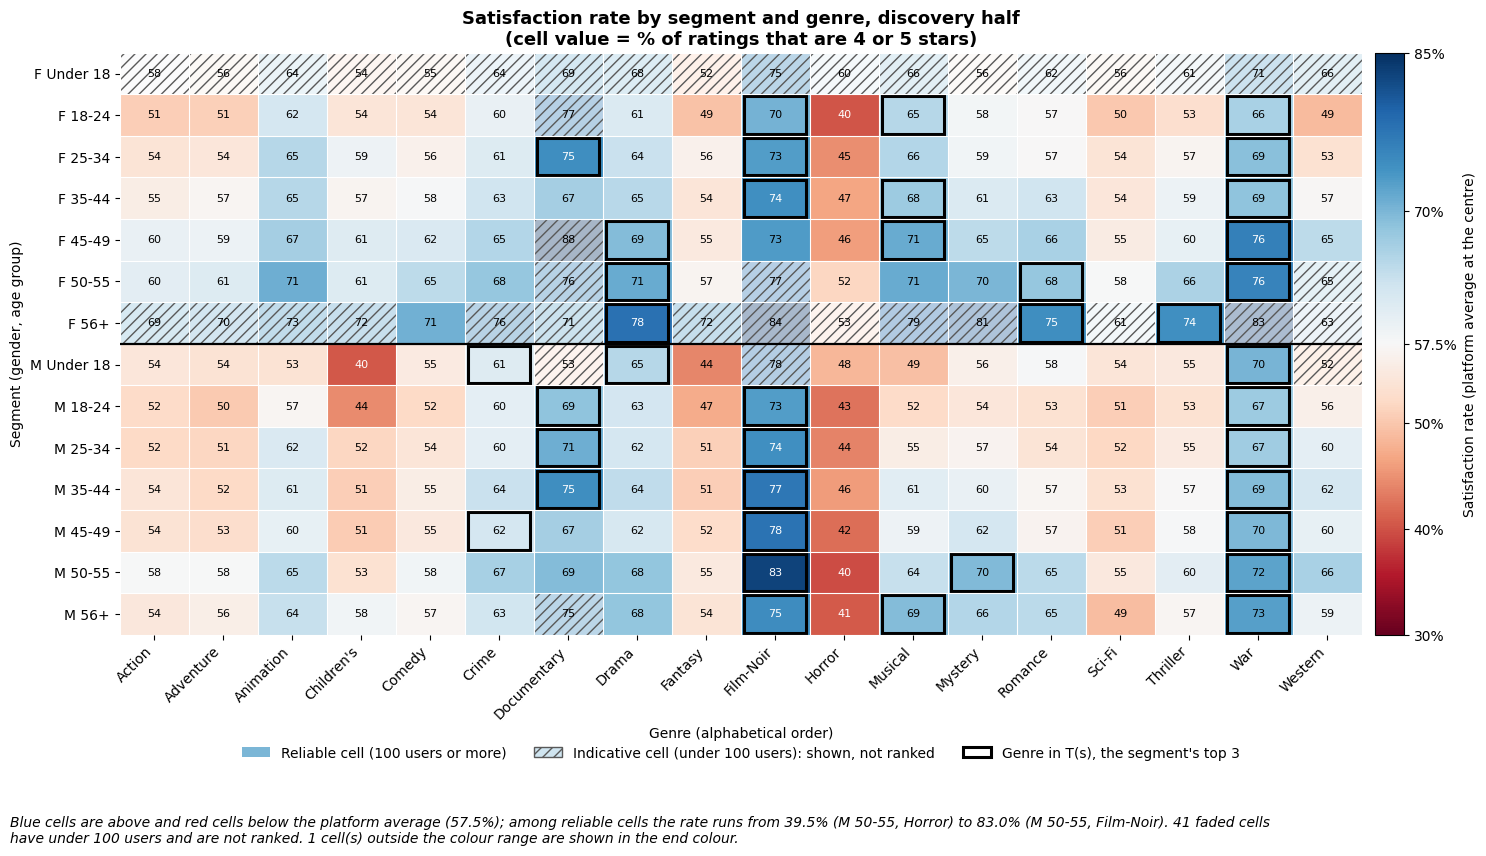

caption: Blue cells are above and red cells below the platform average (57.5%); among reliable cells the rate runs from 39.5% (M 50-55, Horror) to 83.0% (M 50-55, Film-Noir). 41 faded cells have under 100 users and are not ranked. 1 cell(s) outside the colour range are shown in the end colour.


In [5]:
print("STEP B10.1  heatmap of satisfaction rate, discovery half")

disc1 = table1_rates[table1_rates["half"] == "discovery"]

def grid(frame, col):
    wide = frame.pivot(index=["gender", "age_group"], columns="genre", values=col)
    return wide.reindex(index=SEG_INDEX, columns=GENRES)

rate, tier = grid(disc1, "sat_rate"), grid(disc1, "tier")
top3 = grid(table2_lcb, "in_top3")
assert rate.shape == (14, 18) and not rate.isna().any().any(), "heatmap needs 14 x 18 cells without gaps"

cmap = plt.get_cmap(HEAT_CMAP)
norm = TwoSlopeNorm(vmin=HEAT_MIN, vcenter=HEAT_CENTER, vmax=HEAT_MAX)

fig, ax = plt.subplots(figsize=(15, 8.6))
for i in range(14):
    for j in range(18):
        v, reliable = float(rate.iloc[i, j]), tier.iloc[i, j] == "reliable"
        rgba = list(cmap(norm(v)))
        if not reliable:
            rgba[3] = 0.35
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor=rgba, linewidth=0,
                               edgecolor=None if reliable else "0.35", hatch=None if reliable else "///"))
        lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        ax.text(j, i, f"{v * 100:.0f}", ha="center", va="center", fontsize=8,
                color="white" if (reliable and lum < 0.5) else "black")
        if top3.iloc[i, j] is True or top3.iloc[i, j] == True:
            ax.add_patch(Rectangle((j - .45, i - .45), .9, .9, fill=False, edgecolor="black", linewidth=2.2))
ax.hlines(np.arange(-.5, 14), -.5, 17.5, color="white", linewidth=.8)
ax.vlines(np.arange(-.5, 18), -.5, 13.5, color="white", linewidth=.8)
ax.axhline(6.5, color="black", linewidth=1.6)
ax.set_xlim(-.5, 17.5); ax.set_ylim(13.5, -.5)
ax.set_xticks(range(18)); ax.set_xticklabels(GENRES, rotation=45, ha="right")
ax.set_yticks(range(14)); ax.set_yticklabels([SEG_LABEL[s] for s in SEGMENTS])
ax.set_xlabel("Genre (alphabetical order)")
ax.set_ylabel("Segment (gender, age group)")
ax.set_title("Satisfaction rate by segment and genre, discovery half\n(cell value = % of ratings that are 4 or 5 stars)")
for sp in ax.spines.values():
    sp.set_visible(False)

cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.025, pad=0.01,
                    ticks=[HEAT_MIN, .40, .50, HEAT_CENTER, .70, HEAT_MAX])
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:.1f}%" if abs(v - HEAT_CENTER) < 1e-9 else f"{v * 100:.0f}%"))
cbar.set_label("Satisfaction rate (platform average at the centre)")

handles = [Patch(facecolor=cmap(norm(.70)), label="Reliable cell (100 users or more)"),
           Patch(facecolor=(*cmap(norm(.70))[:3], .35), edgecolor="0.35", hatch="///", label="Indicative cell (under 100 users): shown, not ranked"),
           Patch(fill=False, edgecolor="black", linewidth=2.2, label="Genre in T(s), the segment's top 3")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)

rel = disc1[disc1["tier"] == "reliable"]
hi, lo = rel.loc[rel["sat_rate"].idxmax()], rel.loc[rel["sat_rate"].idxmin()]
n_ind = int((tier == "indicative").sum().sum())
n_clip = int(((rate < HEAT_MIN) | (rate > HEAT_MAX)).sum().sum())
caption = (f"Blue cells are above and red cells below the platform average ({HEAT_CENTER:.1%}); among reliable cells the rate runs from "
           f"{lo['sat_rate']:.1%} ({lo['gender']} {lo['age_group']}, {lo['genre']}) to {hi['sat_rate']:.1%} ({hi['gender']} {hi['age_group']}, {hi['genre']}). "
           f"{n_ind} faded cells have under 100 users and are not ranked."
           + (f" {n_clip} cell(s) outside the colour range are shown in the end colour." if n_clip else ""))
finish(fig, caption, "B10_1_heatmap", bottom=0.07)

### Step B10.2: D(s) by Segment with 95% CI
Validation half (Steps B8 and B9). Each tested segment is one dot: D(s) = mean satisfaction rate of its own top 3 minus that of the common top 3 (B), with the unadjusted 95% bootstrap CI. **Colour shows the conclusion after Holm correction**, not whether the CI contains 0. Segments that were not tested have no dot; the reason is written on their row.

STEP B10.2  D(s) with CI by segment, validation half


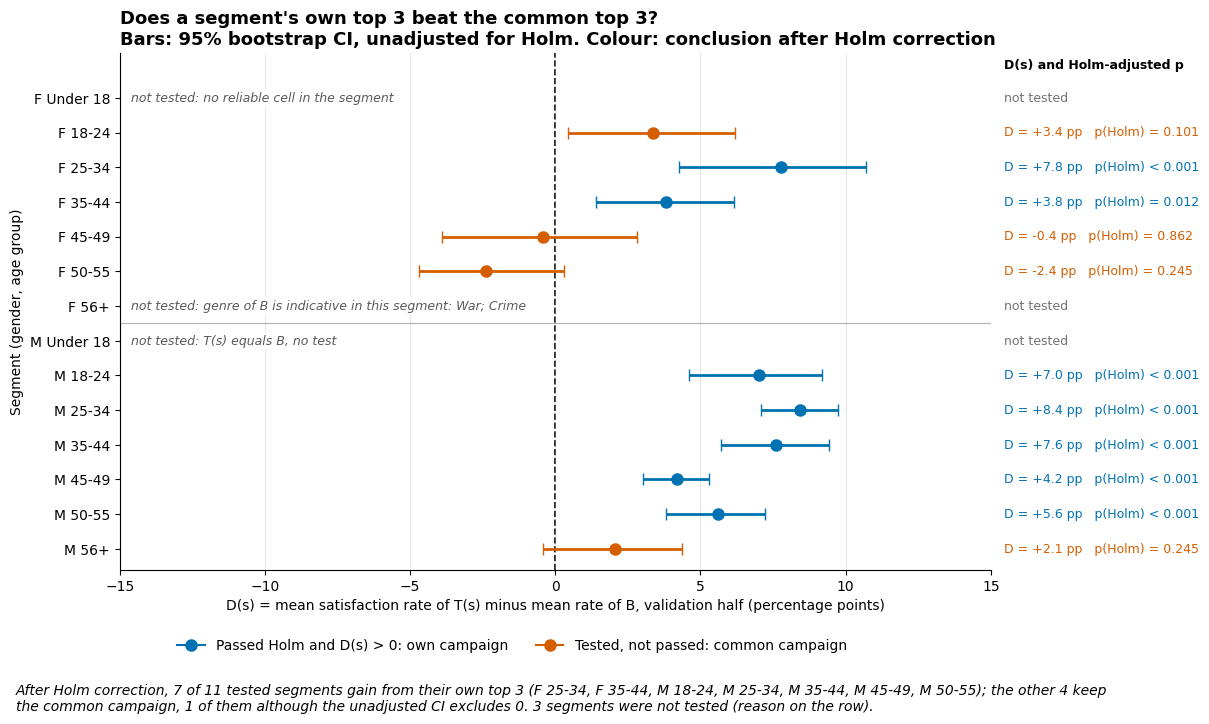

caption: After Holm correction, 7 of 11 tested segments gain from their own top 3 (F 25-34, F 35-44, M 18-24, M 25-34, M 35-44, M 45-49, M 50-55); the other 4 keep the common campaign, 1 of them although the unadjusted CI excludes 0. 3 segments were not tested (reason on the row).


In [6]:
print("STEP B10.2  D(s) with CI by segment, validation half")

seg_order = pd.DataFrame(SEGMENTS, columns=["gender", "age_group"])
res = seg_order.merge(table3_results, on=["gender", "age_group"], how="left", validate="1:1")
assert len(res) == 14 and res["category"].notna().all(), "table3_results must have one row per segment"
tested = res["category"].isin(["passed", "not_passed"])
m = int(tested.sum())
assert m == int(table3_results["m"].iloc[0]), "m in table3_results differs from the number of tested rows"

pp = lambda x: x * 100
lim = max(D_HALF_RANGE_PP, 5 * ceil(max(abs(pp(res.loc[tested, "ci_low"])).max(), abs(pp(res.loc[tested, "ci_high"])).max()) / 5)) if m else D_HALF_RANGE_PP

fig, ax = plt.subplots(figsize=(13, 7.6))
ax.axvline(0, color="black", linestyle="--", linewidth=1.2, zorder=1)
for k, row in res.iterrows():
    if tested[k]:
        col = COLORS[row["category"]]
        ax.errorbar(pp(row["d"]), k, xerr=[[pp(row["d"] - row["ci_low"])], [pp(row["ci_high"] - row["d"])]],
                    fmt="o", color=col, ecolor=col, elinewidth=2, capsize=4, markersize=8, zorder=3)
        label = f"D = {pp(row['d']):+.1f} pp   p(Holm) {fmt_p(row['p_holm'])}"
        ax.annotate(label, xy=(1.015, k), xycoords=("axes fraction", "data"), va="center", fontsize=9, color=col)
    else:
        why = row["reason"] if str(row["reason"]).strip() else row["category"].replace("_", " ")
        ax.text(-lim + 0.4, k, f"not tested: {why}", va="center", ha="left", fontsize=9, style="italic", color="0.35",
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=2)
        ax.annotate("not tested", xy=(1.015, k), xycoords=("axes fraction", "data"), va="center", fontsize=9, color="0.45")
ax.annotate("D(s) and Holm-adjusted p", xy=(1.015, -0.95), xycoords=("axes fraction", "data"), va="center", fontsize=9, fontweight="bold")
ax.axhline(6.5, color="0.7", linewidth=.8)
ax.set_xlim(-lim, lim); ax.set_ylim(13.6, -1.3)
ax.set_yticks(range(14)); ax.set_yticklabels([SEG_LABEL[s] for s in SEGMENTS])
ax.set_xlabel("D(s) = mean satisfaction rate of T(s) minus mean rate of B, validation half (percentage points)")
ax.set_ylabel("Segment (gender, age group)")
ax.grid(axis="x", alpha=.3)
ax.set_title("Does a segment's own top 3 beat the common top 3?\nBars: 95% bootstrap CI, unadjusted for Holm. Colour: conclusion after Holm correction", loc="left")
ax.legend(handles=[Line2D([], [], marker="o", color=COLORS["passed"], linestyle="-", markersize=8, label="Passed Holm and D(s) > 0: own campaign"),
                   Line2D([], [], marker="o", color=COLORS["not_passed"], linestyle="-", markersize=8, label="Tested, not passed: common campaign")],
          loc="upper center", bbox_to_anchor=(0.45, -0.11), ncol=2, frameon=False)
fig.subplots_adjust(left=0.09, right=0.76, top=0.88, bottom=0.2)

n_pass = int((res["category"] == "passed").sum())
names = ", ".join(res.loc[res["category"] == "passed", "segment"])
n_ci_only = int(((res["category"] == "not_passed") & (res["ci_low"] > 0)).sum())
n_untested = 14 - m
caption = (f"After Holm correction, {n_pass} of {m} tested segments gain from their own top 3" + (f" ({names})" if n_pass else "") +
           f"; the other {m - n_pass} keep the common campaign" +
           (f", {n_ci_only} of them although the unadjusted CI excludes 0" if n_ci_only else "") +
           f". {n_untested} segments were not tested (reason on the row).")
finish(fig, caption, "B10_2_difference_by_segment", tight=False)

### Step B10.3: T(s) against B, Dumbbell
Validation half (Step B8), tested segments only. For each segment the grey square is the mean satisfaction rate of the common top 3 (B) and the circle is the mean rate of the segment's own top 3 T(s); the line between them is D(s). The x-axis starts at 40% (stated on the axis): the chart encodes the position of the dots, not bar lengths, so no bar is cut. Circle colours are the same as in Step B10.2.

STEP B10.3  T(s) against B, dumbbell, validation half


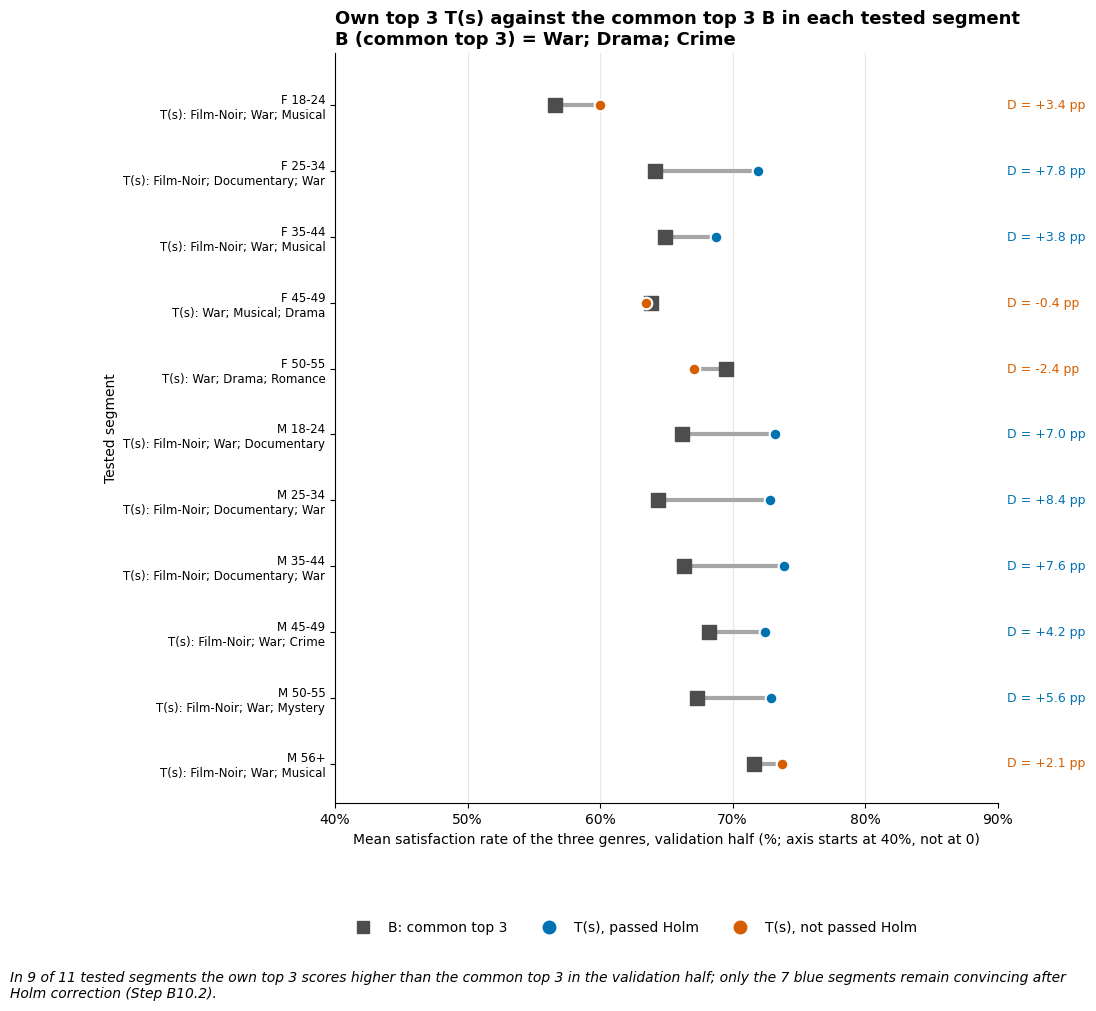

caption: In 9 of 11 tested segments the own top 3 scores higher than the common top 3 in the validation half; only the 7 blue segments remain convincing after Holm correction (Step B10.2).


In [7]:
print("STEP B10.3  T(s) against B, dumbbell, validation half")

td = res[tested].reset_index(drop=True)
if td.empty:
    print("no tested segment: nothing to draw")
else:
    xlim3 = widen(DUMBBELL_XLIM, np.r_[td["mean_r_b"], td["mean_r_ts"]], 0.05)
    fig, ax = plt.subplots(figsize=(12.5, 1.0 + 0.62 * len(td) + 2.6))
    for k, row in td.iterrows():
        col = COLORS[row["category"]]
        ax.plot([row["mean_r_b"], row["mean_r_ts"]], [k, k], color="0.65", linewidth=3, zorder=1)
        ax.scatter(row["mean_r_b"], k, marker="s", s=100, color=COLORS["B"], zorder=2)
        ax.scatter(row["mean_r_ts"], k, marker="o", s=70, color=col, edgecolors="white", linewidths=1.5, zorder=3)
        ax.annotate(f"D = {pp(row['d']):+.1f} pp", xy=(1.015, k), xycoords=("axes fraction", "data"), va="center", fontsize=9, color=col)
    ax.set_yticks(range(len(td)))
    ax.set_yticklabels([f"{r['segment']}\nT(s): {r['t_s']}" for _, r in td.iterrows()], fontsize=8.5)
    ax.set_ylim(len(td) - .4, -.8)
    ax.set_xlim(*xlim3)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel(f"Mean satisfaction rate of the three genres, validation half (%; axis starts at {xlim3[0]:.0%}, not at 0)")
    ax.set_ylabel("Tested segment")
    ax.grid(axis="x", alpha=.3)
    b_txt = f"\nB (common top 3) = {'; '.join(B_GENRES)}" if B_GENRES else ""
    ax.set_title("Own top 3 T(s) against the common top 3 B in each tested segment" + b_txt, loc="left")
    ax.legend(handles=[Line2D([], [], marker="s", color=COLORS["B"], linestyle="", markersize=8, label="B: common top 3"),
                       Line2D([], [], marker="o", color=COLORS["passed"], linestyle="", markersize=9, label="T(s), passed Holm"),
                       Line2D([], [], marker="o", color=COLORS["not_passed"], linestyle="", markersize=9, label="T(s), not passed Holm")],
              loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=3, frameon=False)
    fig.subplots_adjust(left=0.27, right=0.80, top=0.92, bottom=0.2)
    n_higher = int((td["d"] > 0).sum())
    caption = (f"In {n_higher} of {len(td)} tested segments the own top 3 scores higher than the common top 3 in the validation half; "
               f"only the {n_pass} blue segments remain convincing after Holm correction (Step B10.2).")
    finish(fig, caption, "B10_3_dumbbell_ts_vs_b", tight=False)

### Step B10.4: Exploratory, Reach against Satisfaction Rate
**Exploratory. Not used for any recommendation.** Discovery half. Each dot is one of the 252 cells: reach (share of the segment's users who rated that genre) on the x-axis and satisfaction rate on the y-axis. It shows whether the genres that most users watch are also the ones they like, which is a description of the data, not a test.

STEP B10.4  exploratory: reach against satisfaction rate, discovery half
cells: 252, reliable: 211
Spearman rho, all cells      : -0.230
Spearman rho, reliable cells : -0.149


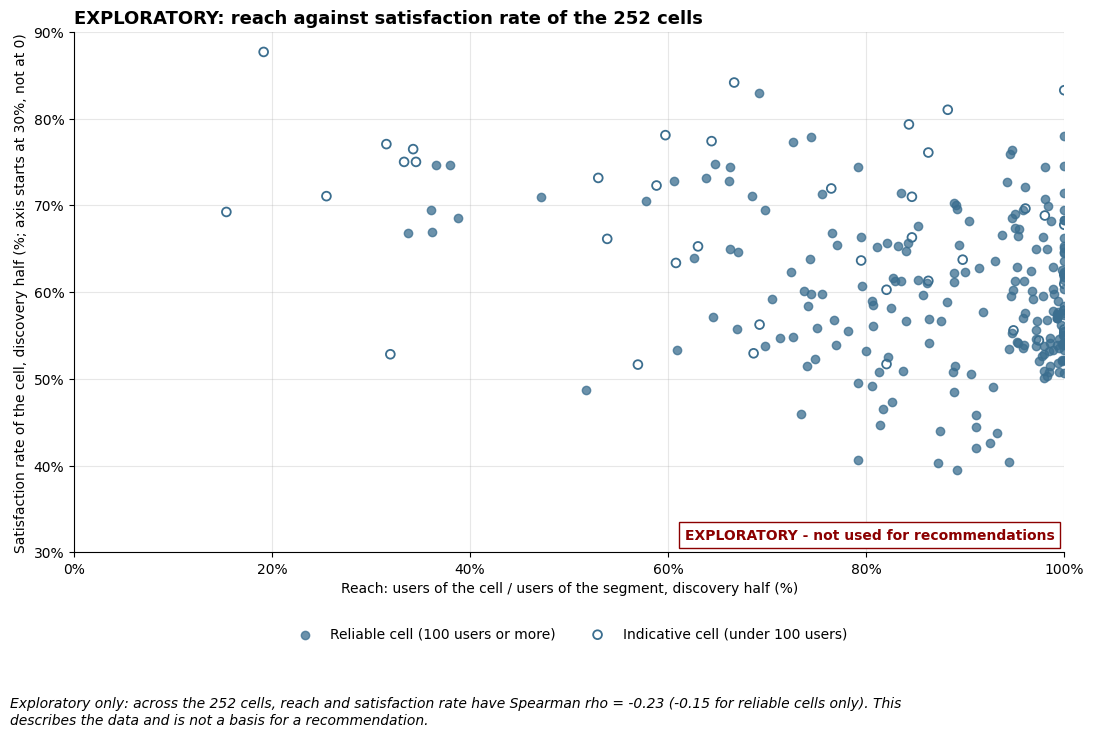

caption: Exploratory only: across the 252 cells, reach and satisfaction rate have Spearman rho = -0.23 (-0.15 for reliable cells only). This describes the data and is not a basis for a recommendation.


In [8]:
print("STEP B10.4  exploratory: reach against satisfaction rate, discovery half")

c4 = table1_rates[table1_rates["half"] == "discovery"].copy()
assert len(c4) == 252, "expected 252 cells in the discovery half"
ylim4 = widen(SCATTER_YLIM, c4["sat_rate"], 0.05)
rho_all = c4["reach"].rank().corr(c4["sat_rate"].rank())
rel4 = c4[c4["tier"] == "reliable"]
rho_rel = rel4["reach"].rank().corr(rel4["sat_rate"].rank())
print(f"cells: {len(c4)}, reliable: {len(rel4)}")
print(f"Spearman rho, all cells      : {rho_all:.3f}")
print(f"Spearman rho, reliable cells : {rho_rel:.3f}")

fig, ax = plt.subplots(figsize=(11, 7.4))
ind = c4[c4["tier"] == "indicative"]
ax.scatter(rel4["reach"], rel4["sat_rate"], s=36, color="#3B6E8F", alpha=.75, label="Reliable cell (100 users or more)", zorder=3)
ax.scatter(ind["reach"], ind["sat_rate"], s=40, facecolors="none", edgecolors="#3B6E8F", linewidths=1.3,
           label="Indicative cell (under 100 users)", zorder=3)
ax.set_xlim(*SCATTER_XLIM); ax.set_ylim(*ylim4)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Reach: users of the cell / users of the segment, discovery half (%)")
ax.set_ylabel(f"Satisfaction rate of the cell, discovery half (%; axis starts at {ylim4[0]:.0%}, not at 0)")
ax.grid(alpha=.3)
ax.set_title("EXPLORATORY: reach against satisfaction rate of the 252 cells", loc="left")
ax.text(0.99, 0.02, "EXPLORATORY - not used for recommendations", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=10, fontweight="bold", color="#8B0000", bbox=dict(facecolor="white", edgecolor="#8B0000", pad=4))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
caption = (f"Exploratory only: across the {len(c4)} cells, reach and satisfaction rate have Spearman rho = {rho_all:.2f} "
           f"({rho_rel:.2f} for reliable cells only). This describes the data and is not a basis for a recommendation.")
finish(fig, caption, "B10_4_exploratory_reach_vs_rate")

## Notes for the merge and for the presentation
**Inputs.** The charts read the tables of Steps B3 to B9 as they are; no number is recomputed here. All numbers in the captions are printed by the same Step. The schema check stops the notebook if a column or label differs from `D3_columns_HoangQuan_v2`; if the column file changes again, only `SCHEMA` and the column names used in Steps B10.1 to B10.4 need updating.

**Self-check against the brief.**
- Scales were frozen before any real number existed (design table at the top); the only changes made after seeing the data are the widening rules written there (B10.1 colour range unchanged; B10.2 range widened because a CI end exceeded 10 pp; see the printed values).
- No bar chart is used. Axes that do not start at 0 (B10.3, B10.4) say so in the axis label and encode position, not length.
- The "measure may differ" note of the D2 charts is gone: D(s) is computed on ratings, like the satisfaction rate.
- Colour in B10.2 follows the Holm conclusion. Segments not tested show their reason. CI is labelled "unadjusted".
- Every number in a caption is printed from the data in the same Step; no figure is typed by hand except the frozen scales and the platform average used as colour centre.

**Why these chart types (questions for the presentation).**
- B10.1 heatmap: 252 cells need a matrix, and position plus colour lets the team find strong and weak genres per segment in seconds; the hatch keeps thin cells visible but visibly less certain.
- B10.2 dot with interval: the question is "is the difference above 0?", so the zero line and the CI are the whole message; colour follows the Holm decision because that is the rule agreed in D1.
- B10.3 dumbbell: shows the two scores being compared and the gap between them on one common scale, without drawing bars from a cut-off baseline.
- B10.4 scatter: reach and rate are two continuous measures per cell; a scatter shows the relationship (or its absence) and is labelled exploratory.

**What a reader should take from chart 2.** Whether a segment's own campaign is supported is decided by the colour (the Holm result), not by how large D(s) looks or by whether the unadjusted CI touches 0. A blue dot means "use the segment's own top 3"; an orange dot or an untested row means "keep the common campaign".